# Bab 5 — Classification

### Identitas Mahasiswa

| Detail | Identitas |
|---|---|
| Nama | Hadi Nugroho |
| NIM | 101032330235 |

**Tujuan pembelajaran.** memprediksi kelas biner (pinjaman *default* vs *paid off*) dengan naive Bayes, linear discriminant analysis, dan regresi logistik; menafsirkan log-odds serta odds ratio; mengevaluasi classifier dengan confusion matrix, precision/recall/specificity, ROC, AUC, dan lift; memilih strategi untuk kelas langka; membandingkan batas keputusan beberapa model.

**Ringkasan bab.** Classification memprediksi kategori, biasanya dengan mengestimasi probabilitas setiap kelas lalu menerapkan cutoff. Naive Bayes menggabungkan probabilitas kondisional tiap prediktor dengan asumsi independen bersyarat. LDA mencari kombinasi linear prediktor yang paling memisahkan kelas. Regresi logistik memodelkan log-odds sebagai fungsi linear prediktor dan menjadi bagian dari keluarga GLM. Akurasi saja menyesatkan ketika kelas yang dicari jarang; precision, recall, specificity, ROC/AUC, dan lift memberi gambaran lebih lengkap. Undersampling, up-weighting, dan data sintetis (SMOTE) terutama menggeser probabilitas dan cutoff, bukan otomatis menambah kemampuan membedakan kelas.

Notebook belajar dan reproduksi edisi kedua (Bruce, Bruce, Gedeck, 2020). Penjelasan ditulis ulang dengan bantuan AI; kode diadaptasi dari repository resmi berlisensi GPL-3.0. Bagian tambahan diberi label. Nomor halaman merujuk halaman cetak; nomor PDF = cetak + 18.

## Setup dan dataset

| File | Unit observasi dan kolom | Makna |
|---|---|---|
| `loan_data.csv.gz` | 45.342 pinjaman Lending Club; 21 kolom | Sampel **seimbang** 22.671 default dan 22.671 paid off. Buku memakainya sebagai contoh data hasil undersampling |
| `loan3000.csv` | 3.000 pinjaman; 1.445 default, 1.555 paid off | Subset dua prediktor untuk visualisasi LDA dan batas keputusan |
| `full_train_set.csv.gz` | 119.987 pinjaman; 18,89% default | Data tidak seimbang untuk bagian kelas langka; tidak memuat `borrower_score` |
| Target | `outcome` (`default` / `paid off`) | Kelas positif notebook ini adalah **default** (Y=1), kelas yang ingin dideteksi |
| Prediktor kategori | `purpose_` (7 level), `home_` (MORTGAGE/OWN/RENT), `emp_len_` (`< 1 Year`/`> 1 Year`, diawali spasi di CSV) | Tujuan pinjaman, status kepemilikan rumah, lama bekerja |
| Prediktor numerik | `payment_inc_ratio`, `dti`, `revol_bal`, `revol_util`, `borrower_score` | Rasio cicilan terhadap pendapatan, debt-to-income, saldo kredit revolving (USD), utilisasi revolving (%), skor peminjam 0–1 |

`borrower_score` adalah fitur turunan yang dibuat buku dengan KNN dari kolom kredit lain dan **outcome** pada data yang sama (Bab 6, *KNN as a Feature Engine*). Kolom `status` (Charged Off/Default/Fully Paid) adalah status asli yang menentukan `outcome`, sehingga tidak dipakai sebagai prediktor karena membocorkan target. Kolom `Unnamed: 0` menyimpan nomor baris asal (dimulai dari 1, seperti R); indeks pandas dimulai dari 0.

Satuan `payment_inc_ratio` dan `dti` tidak dicantumkan eksplisit di CSV, jadi label grafik memakai skala dataset. Data adalah contoh historis Lending Club yang disediakan buku.

Sumber file: [repository pendamping edisi kedua](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa/data). Commit sumber dan checksum dicatat di `data/manifest.json`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from importlib.metadata import version

ROOT = Path.cwd()
if not (ROOT / "data/manifest.json").exists():
    raise FileNotFoundError("Buka folder proyek sebagai workspace dan jalankan notebook dari root proyek.")
DATA = ROOT / "data"
SEED = 1
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 25)
print("Python:", sys.version.split()[0])
print("Data:", DATA.relative_to(ROOT))
print("Versi:", {lib: version(lib) for lib in ["numpy", "pandas", "scikit-learn", "statsmodels", "imbalanced-learn", "pygam"]})

from sklearn.naive_bayes import MultinomialNB, CategoricalNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support, roc_curve,
                             roc_auc_score, accuracy_score)
import statsmodels.api as sm
import statsmodels.formula.api as smf
from imblearn.over_sampling import SMOTE, ADASYN
from pygam import LogisticGAM, s

def load_loans(name):
    df = pd.read_csv(DATA / name)
    df["outcome"] = pd.Categorical(df["outcome"], categories=["paid off", "default"])
    df["y"] = (df["outcome"] == "default").astype(int)   # 1 = default (kelas positif)
    return df

def unpenalized_logit():
    # Pengganti penalty='l2', C=1e42, solver='liblinear' pada kode buku (lihat bagian GLM)
    return LogisticRegression(C=np.inf, solver="newton-cholesky", max_iter=500)

loan_data = load_loans("loan_data.csv.gz")
loan3000 = load_loans("loan3000.csv")
full_train_set = load_loans("full_train_set.csv.gz")
for name, df in [("loan_data", loan_data), ("loan3000", loan3000), ("full_train_set", full_train_set)]:
    assert df.notna().all().all(), name
    print(f"{name:15s} {df.shape}  default={df.y.sum():,}  paid off={(1 - df.y).sum():,}  "
          f"proporsi default={df.y.mean():.4f}")
assert loan_data.y.sum() == 22671 and len(loan_data) == 45342
assert len(full_train_set) == 119987
display(loan_data.drop(columns="y").head())

Python: 3.13.16
Data: data
Versi: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0', 'imbalanced-learn': '0.14.2', 'pygam': '0.12.0'}


loan_data       (45342, 22)  default=22,671  paid off=22,671  proporsi default=0.5000
loan3000        (3000, 7)  default=1,445  paid off=1,555  proporsi default=0.4817
full_train_set  (119987, 20)  default=22,671  paid off=97,316  proporsi default=0.1889


,Unnamed: 0,status,loan_amnt,term,annual_inc,dti,payment_inc_ratio,revol_bal,revol_util,purpose,home_ownership,delinq_2yrs_zero,pub_rec_zero,open_acc,grade,outcome,emp_length,purpose_,home_,emp_len_,borrower_score
0,1,Charged Off,2500,60 months,30000,1.00,2.39320,1687,9.4,car,RENT,1,1,3,4.8,default,1,major_purchase,RENT,> 1 Year,0.65
1,2,Charged Off,5600,60 months,40000,5.55,4.57170,5210,32.6,small_business,OWN,1,1,11,1.4,default,5,small_business,OWN,> 1 Year,0.80
2,3,Charged Off,5375,60 months,15000,18.08,9.71600,9279,36.5,other,RENT,1,1,2,6.0,default,1,other,RENT,> 1 Year,0.60
3,4,Charged Off,9000,36 months,30000,10.08,12.21520,10452,91.7,debt_consolidation,RENT,1,1,4,4.2,default,1,debt_consolidation,RENT,> 1 Year,0.50
4,5,Charged Off,10000,36 months,100000,7.06,3.90888,11997,55.5,other,RENT,1,1,14,5.4,default,4,other,RENT,> 1 Year,0.55


<a id="c5-01"></a>
## Naive Bayes

*Acuan: cetak 196; PDF 214. Jenis: Teori.*

Naive Bayes memakai probabilitas melihat nilai prediktor **jika kelasnya diketahui**, $P(X\mid Y=i)$, untuk memperkirakan besaran yang sebenarnya kita butuhkan: probabilitas kelas **jika prediktornya diketahui**, $P(Y=i\mid X)$. Dalam pemakaian dasar buku, semua prediktor berupa kategori.

Istilah kunci: **conditional probability** $P(A\mid B)$ (peluang A dengan syarat B terjadi) dan **posterior probability** (peluang kelas setelah informasi prediktor diperhitungkan). Teorema Bayes menghubungkan keduanya: $P(Y\mid X)=P(X\mid Y)P(Y)/P(X)$. Prior $P(Y)$ adalah proporsi kelas sebelum melihat prediktor.

<a id="c5-02"></a>
## Why Exact Bayesian Classification Is Impractical

*Acuan: cetak 197; PDF 215. Jenis: Teori + demonstrasi tambahan pada data buku.*

Klasifikasi Bayes **exact** untuk record baru: cari semua record latih dengan profil prediktor yang persis sama, lalu hitung proporsi setiap kelas di kelompok itu. Cara ini benar secara konsep, tetapi jumlah kombinasi profil tumbuh secara eksponensial: lima prediktor biner sudah menghasilkan $2^5=32$ profil, dan prediktor dengan banyak level membuat sebagian besar profil hanya punya sedikit atau nol record yang cocok.

**Tambahan demonstrasi:** sel berikut menghitung klasifikasi exact untuk pinjaman indeks 146 (baris ke-147 versi R, contoh buku) memakai tiga prediktor kategori, lalu memperlihatkan bagaimana profil menjadi unik ketika prediktor ditambah.

In [2]:
nb_predictors = ["purpose_", "home_", "emp_len_"]
profile_146 = loan_data.loc[146, nb_predictors]
print("Record indeks 146 (Unnamed: 0 =", loan_data.loc[146, "Unnamed: 0"], "):", profile_146.to_dict(),
      "| outcome sebenarnya:", loan_data.loc[146, "outcome"])
match = (loan_data[nb_predictors] == profile_146).all(axis=1)
exact_bayes = loan_data.loc[match, "outcome"].value_counts(normalize=True)
print(f"Record dengan profil persis sama: {match.sum():,}")
display(exact_bayes.rename("proporsi (Bayes exact)").to_frame())

growing = ["purpose_", "home_", "emp_len_", "term", "delinq_2yrs_zero", "pub_rec_zero", "grade", "emp_length", "open_acc"]
rows = []
for k in range(1, len(growing) + 1):
    cols = growing[:k]
    profile_size = loan_data.groupby(cols, observed=True).size()
    record_profile_size = loan_data.groupby(cols, observed=True)[cols[0]].transform("size")
    rows.append({"prediktor ke-": k, "ditambah": cols[-1],
                 "kombinasi mungkin": int(np.prod([loan_data[c].nunique() for c in cols])),
                 "profil teramati": len(profile_size),
                 "% record berprofil unik": 100 * (record_profile_size == 1).mean(),
                 "median record per profil": profile_size.median()})
display(pd.DataFrame(rows))

Record indeks 146 (Unnamed: 0 = 147 ): {'purpose_': 'small_business', 'home_': 'MORTGAGE', 'emp_len_': ' > 1 Year'} | outcome sebenarnya: default
Record dengan profil persis sama: 706


,proporsi (Bayes exact)
outcome,
default,0.651558
paid off,0.348442


,prediktor ke-,ditambah,kombinasi mungkin,profil teramati,% record berprofil unik,median record per profil
0,1,purpose_,7,7,0.000000,2977.0
1,2,home_,21,21,0.000000,722.0
2,3,emp_len_,42,42,0.000000,176.5
3,4,term,84,82,0.002205,81.0
4,5,delinq_2yrs_zero,168,154,0.028671,38.5
5,6,pub_rec_zero,336,270,0.063958,15.5
6,7,grade,11760,3577,2.761237,2.0
7,8,emp_length,141120,11939,13.395968,1.0
8,9,open_acc,6632640,31826,54.878479,1.0


**Interpretasi dan catatan belajar.** Dengan tiga prediktor, profil record 146 masih memiliki ratusan pasangan sehingga proporsi exact bisa dihitung. Setelah `grade`, `emp_length`, dan `open_acc` ditambahkan, jumlah kombinasi mencapai jutaan dan sebagian besar record menjadi unik: proporsi kelas pada "kelompok" berisi satu record tidak berguna untuk memprediksi data baru. Inilah alasan perlunya penyederhanaan naive Bayes.

<a id="c5-03"></a>
## The Naive Solution

*Acuan: cetak 198; PDF 216. Jenis: Reproduksi Python buku + verifikasi rumus.*

Naive Bayes tidak mencari profil yang persis sama. Untuk setiap kelas, hitung probabilitas kondisional **tiap prediktor secara terpisah**, kalikan dengan prior, lalu normalisasi agar jumlah probabilitas semua kelas = 1:

$$P(Y=i\mid X_1,\dots,X_p)=\frac{P(Y=i)\prod_{j=1}^{p}P(X_j\mid Y=i)}{\sum_{k}P(Y=k)\prod_{j=1}^{p}P(X_j\mid Y=k)}$$

Asumsi "naive": prediktor **independen bersyarat** pada kelas. Asumsi ini jarang benar, sehingga probabilitas yang dihasilkan cenderung bias; namun bila tujuannya hanya **mengurutkan** record dari yang paling mungkin default, peringkatnya sering tetap berguna.

Kode buku memakai `MultinomialNB` pada dummy one-hot. Karena setiap record memiliki tepat satu dummy aktif per prediktor, model multinomial ini setara dengan naive Bayes kategorikal (konstanta pembagi sama untuk semua kelas). `alpha=1e-10` praktis menghilangkan Laplace smoothing; `fit_prior=False` memakai prior seragam, sama dengan prior empiris karena data seimbang. **Tambahan:** perhitungan manual rumus di atas dan `CategoricalNB` dipakai sebagai pemeriksa.

In [3]:
X_nb = pd.get_dummies(loan_data[nb_predictors], prefix="", prefix_sep="", dtype=int)
y_label = loan_data["outcome"].astype(str)
naive_model = MultinomialNB(alpha=1e-10, fit_prior=False).fit(X_nb, y_label)
new_loan = X_nb.loc[146:146]
proba_nb = pd.DataFrame(naive_model.predict_proba(new_loan), columns=naive_model.classes_)
print("Kelas prediksi naive Bayes:", naive_model.predict(new_loan)[0])
display(proba_nb.rename(index={0: "record 146"}))

# Verifikasi: prior x perkalian probabilitas kondisional tiap prediktor
rows = []
for cls in ["default", "paid off"]:
    subset = loan_data[loan_data.outcome == cls]
    row = {"kelas": cls, "P(Y)": (loan_data.outcome == cls).mean()}
    row.update({f"P({v}={profile_146[v].strip()} | Y)": (subset[v] == profile_146[v]).mean() for v in nb_predictors})
    rows.append(row)
manual_nb = pd.DataFrame(rows).set_index("kelas")
manual_nb["pembilang"] = manual_nb.prod(axis=1)
manual_nb["posterior naive"] = manual_nb["pembilang"] / manual_nb["pembilang"].sum()
display(manual_nb)
np.testing.assert_allclose(manual_nb.loc[proba_nb.columns, "posterior naive"], proba_nb.iloc[0], rtol=1e-6)

codes = loan_data[nb_predictors].apply(lambda col: col.astype("category").cat.codes)
cat_nb = CategoricalNB(alpha=1e-10).fit(codes, y_label)
np.testing.assert_allclose(cat_nb.predict_proba(codes.loc[146:146]), naive_model.predict_proba(new_loan), rtol=1e-6)
print("Bayes exact (profil sama) P(default) =", round(exact_bayes["default"], 4),
      "| naive Bayes P(default) =", round(proba_nb.loc[0, "default"], 4))

Kelas prediksi naive Bayes: default


,default,paid off
record 146,0.653699,0.346301


,P(Y),P(purpose_=small_business | Y),P(home_=MORTGAGE | Y),P(emp_len_=> 1 Year | Y),pembilang,posterior naive
kelas,,,,,,
default,0.5,0.045741,0.431344,0.952715,0.009399,0.653699
paid off,0.5,0.020996,0.489480,0.968947,0.004979,0.346301


Bayes exact (profil sama) P(default) = 0.6516 | naive Bayes P(default) = 0.6537


**Interpretasi dan catatan belajar.** Naive Bayes memprediksi record 146 sebagai **default** dengan probabilitas sekitar 0,654 (paid off ≈0,346), sama dengan output buku. Kontribusi terbesar berasal dari `small_business`: proporsinya pada kelompok default (≈4,6%) lebih dari dua kali kelompok paid off (≈2,1%). Untuk profil ini, Bayes exact pada 706 record yang cocok memberi 0,652, sangat dekat dengan naive 0,654; dengan hanya tiga prediktor, ketergantungan antarprediktor tampaknya lemah. Ketika prediktor bertambah dan saling berkaitan, selisih exact–naive dapat membesar, tetapi justru saat itu Bayes exact tidak lagi bisa dihitung. Ingat bahwa kedua angka dihitung pada data seimbang, sehingga belum mencerminkan prior default di populasi pinjaman sebenarnya.

<a id="c5-04"></a>
## Numeric Predictor Variables

*Acuan: cetak 200; PDF 218. Jenis: Padanan Python contoh tambahan repository (bukan teks utama buku).*

Naive Bayes dasar membutuhkan prediktor kategori. Untuk prediktor numerik ada dua pendekatan yang dibahas buku: (1) **binning**, yaitu mengubah angka menjadi interval lalu memperlakukannya sebagai kategori; atau (2) memakai **model probabilitas**, misalnya distribusi normal, untuk memperkirakan $P(X_j\mid Y=i)$. Jika suatu level kategori tidak pernah muncul pada data latih untuk kelas tertentu, probabilitasnya nol dan seluruh perkalian ikut nol; smoothing (misalnya Laplace, parameter `alpha`) mencegah masalah ini.

Repository resmi hanya menyediakan sketsa R untuk contoh ini (scikit-learn tidak mencampur prediktor numerik dan kategorikal dalam satu model naive Bayes). Sel berikut membuat padanannya: densitas normal `borrower_score` per kelas, lalu binning skor dan memasukkannya bersama tiga prediktor kategori.

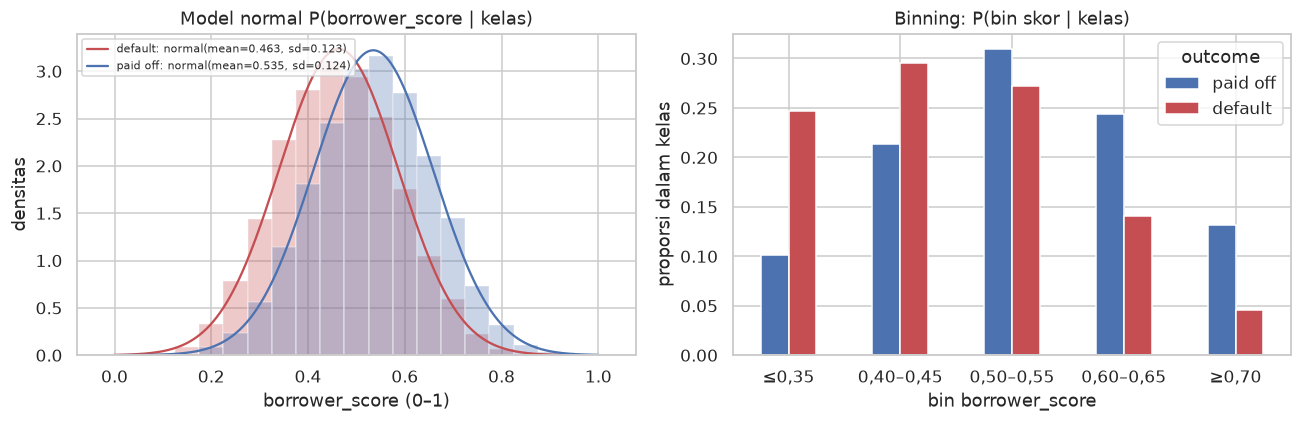

outcome,paid off,default
borrower_score,,
"≤0,35",0.102,0.247
"0,40–0,45",0.213,0.295
"0,50–0,55",0.310,0.273
"0,60–0,65",0.243,0.140
"≥0,70",0.132,0.046


Record 146 borrower_score = 0.55 | P(default) naive Bayes + bin skor = 0.6244


In [4]:
grid = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, color in [("default", "C3"), ("paid off", "C0")]:
    vals = loan_data.loc[loan_data.outcome == cls, "borrower_score"]
    axes[0].hist(vals, bins=np.arange(-0.025, 1.05, 0.05), density=True, alpha=.3, color=color)
    axes[0].plot(grid, stats.norm.pdf(grid, vals.mean(), vals.std()), color=color,
                 label=f"{cls}: normal(mean={vals.mean():.3f}, sd={vals.std():.3f})")
axes[0].set(title="Model normal P(borrower_score | kelas)", xlabel="borrower_score (0–1)", ylabel="densitas")
axes[0].legend(fontsize=7, loc="upper left")

score_bin = pd.cut(loan_data.borrower_score, bins=[-0.01, 0.35, 0.45, 0.55, 0.65, 1.0],
                   labels=["≤0,35", "0,40–0,45", "0,50–0,55", "0,60–0,65", "≥0,70"])
bin_table = pd.crosstab(score_bin, loan_data.outcome, normalize="columns")
bin_table.plot.bar(ax=axes[1], color=["C0", "C3"], rot=0)
axes[1].set(title="Binning: P(bin skor | kelas)", xlabel="bin borrower_score", ylabel="proporsi dalam kelas")
plt.tight_layout(); plt.show()
display(bin_table.style.format("{:.3f}"))

X_nb_bin = pd.concat([X_nb, pd.get_dummies(score_bin, prefix="score", dtype=int)], axis=1)
nb_with_score = MultinomialNB(alpha=1e-10, fit_prior=False).fit(X_nb_bin, y_label)
print("Record 146 borrower_score =", loan_data.loc[146, "borrower_score"],
      "| P(default) naive Bayes + bin skor =",
      round(nb_with_score.predict_proba(X_nb_bin.loc[146:146])[0, list(nb_with_score.classes_).index("default")], 4))

**Interpretasi dan catatan belajar.** Distribusi skor kelompok default bergeser ke kiri, tetapi kedua kelas sangat tumpang tindih. Kurva normal hanya pendekatan: `borrower_score` diskret (kelipatan 0,05) dan terbatas di 0–1. Binning tidak mengasumsikan bentuk distribusi, tetapi batas bin adalah pilihan analis dan informasi di dalam bin hilang. Record 146 memiliki skor 0,55 (di atas rata-rata kelompok default), sehingga P(default) turun dari ≈0,654 menjadi ≈0,624 setelah bin skor ditambahkan. Perubahan ini menunjukkan informasi baru masuk ke perhitungan, bukan bukti bahwa model baru lebih akurat tanpa validasi terpisah.

<a id="c5-05"></a>
## Discriminant Analysis

*Acuan: cetak 201; PDF 219. Jenis: Teori.*

Discriminant analysis adalah classifier statistik paling awal (R. A. Fisher, 1936). **Linear discriminant analysis (LDA)** paling sering dipakai. Selain mengklasifikasikan, bobot diskriminan juga menunjukkan kombinasi prediktor yang paling memisahkan kelas, sehingga LDA dapat dipakai untuk reduksi dimensi dan memahami kontribusi relatif prediktor.

Istilah kunci: **covariance** (arah dan kekuatan variasi bersama dua variabel), **discriminant function** (fungsi prediktor yang memaksimalkan pemisahan kelas), dan **discriminant weights** (bobot hasil fungsi tersebut). LDA klasik mengasumsikan prediktor berdistribusi normal multivariat dalam tiap kelas dengan **matriks kovarians yang sama** untuk semua kelas; varian quadratic discriminant analysis (QDA) melonggarkan asumsi kovarians sama. Dalam praktik, LDA sering tetap bekerja cukup baik meskipun asumsinya tidak dipenuhi sempurna.

<a id="c5-06"></a>
## Covariance Matrix

*Acuan: cetak 202; PDF 220. Jenis: Teori + perhitungan pada data buku.*

Kovarians sampel dua variabel $x$ dan $z$ adalah $s_{x,z}=\sum_{i=1}^{n}(x_i-\bar x)(z_i-\bar z)/(n-1)$. Tanda positif berarti keduanya cenderung naik bersama. Berbeda dari korelasi, kovarians bergantung pada skala variabel. Matriks kovarians menyusun varians di diagonal dan kovarians antarpasangan di luar diagonal:

$$\hat\Sigma=\begin{bmatrix}s_x^2 & s_{x,z}\\ s_{x,z} & s_z^2\end{bmatrix}$$

LDA memakai matriks kovarians **within-class** (gabungan/pooled), yaitu variasi di sekitar mean masing-masing kelas, bukan kovarians seluruh data. **Tambahan:** sel berikut menghitung keduanya dan memeriksa `covariance_` scikit-learn.

In [5]:
lda_predictors = ["borrower_score", "payment_inc_ratio"]
X_lda = loan3000[lda_predictors]
y_lda = loan3000["outcome"].astype(str)
display(X_lda.cov().style.format("{:.5f}").set_caption("Kovarians seluruh data (n−1)"))

centered = X_lda - X_lda.groupby(y_lda).transform("mean")
scatter_within = centered.T @ centered
pooled_cov = scatter_within / (len(X_lda) - y_lda.nunique())
display(pooled_cov.style.format("{:.5f}").set_caption("Kovarians within-class pooled (n−K)"))

loan_lda = LinearDiscriminantAnalysis(store_covariance=True).fit(X_lda, y_lda)
# scikit-learn menyimpan rata-rata berbobot prior dari kovarians bias tiap kelas = scatter_within / n
np.testing.assert_allclose(loan_lda.covariance_, scatter_within / len(X_lda), rtol=1e-10)
print("Korelasi within-class:", round(pooled_cov.iloc[0, 1] / np.sqrt(pooled_cov.iloc[0, 0] * pooled_cov.iloc[1, 1]), 4))

,borrower_score,payment_inc_ratio
borrower_score,0.01646,-0.06040
payment_inc_ratio,-0.06040,18.45828


,borrower_score,payment_inc_ratio
borrower_score,0.01501,-0.03381
payment_inc_ratio,-0.03381,17.97713


Korelasi within-class: -0.0651


**Interpretasi dan catatan belajar.** Kovarians `borrower_score`–`payment_inc_ratio` kecil dan negatif; angka kovarians tidak bisa dibandingkan langsung karena satuan kedua variabel berbeda, sehingga korelasi within-class ditampilkan sebagai ukuran tanpa satuan. Pembagi `n−K` dan `n` hanya mengubah skala matriks, bukan arah diskriminan.

<a id="c5-07"></a>
## Fisher’s Linear Discriminant

*Acuan: cetak 203; PDF 221. Jenis: Teori + verifikasi tambahan.*

Untuk dua prediktor $x,z$ dan kelas biner, Fisher mencari bobot $w_x,w_z$ sehingga skor $w_xx+w_zz$ memaksimalkan rasio

$$\frac{SS_{between}}{SS_{within}},$$

yaitu jarak kuadrat antar-mean kelas dibandingkan variasi di dalam kelas. Proyeksi yang baik menjauhkan pusat kelas sekaligus membuat tiap kelas rapat. Solusinya sebanding dengan $\hat\Sigma_{within}^{-1}(\bar{\mathbf x}_1-\bar{\mathbf x}_0)$.

**Tambahan verifikasi:** arah `scalings_` scikit-learn dibandingkan dengan rumus tersebut, lalu rasio Fisher arah LDA dibandingkan dengan 2.000 arah acak.

In [6]:
means = X_lda.groupby(y_lda).mean()
w_formula = np.linalg.solve(pooled_cov, (means.loc["paid off"] - means.loc["default"]).to_numpy())
ratio = w_formula / loan_lda.scalings_[:, 0]
print("w rumus Fisher:", w_formula.round(4), "| scalings_:", loan_lda.scalings_[:, 0].round(4),
      "| rasio elemen:", ratio.round(4))
assert np.allclose(ratio, ratio[0])

def fisher_ratio(w):
    score = X_lda.to_numpy() @ w
    groups = [score[y_lda == cls] for cls in ["default", "paid off"]]
    between = sum(len(g) * (g.mean() - score.mean()) ** 2 for g in groups)
    within = sum(((g - g.mean()) ** 2).sum() for g in groups)
    return between / within

rng = np.random.default_rng(SEED)
random_dirs = rng.normal(size=(2000, 2)) / X_lda.std().to_numpy()
random_ratios = np.array([fisher_ratio(w) for w in random_dirs])
print(f"Rasio Fisher arah LDA = {fisher_ratio(loan_lda.scalings_[:, 0]):.5f}; "
      f"maksimum 2.000 arah acak = {random_ratios.max():.5f}; "
      f"hanya borrower_score = {fisher_ratio(np.array([1.0, 0.0])):.5f}")
assert fisher_ratio(loan_lda.scalings_[:, 0]) >= random_ratios.max() - 1e-12

w rumus Fisher: [ 4.926  -0.0684] | scalings_: [ 7.1782 -0.0997] | rasio elemen: [0.6862 0.6862]


Rasio Fisher arah LDA = 0.11773; maksimum 2.000 arah acak = 0.11773; hanya borrower_score = 0.09679


**Interpretasi dan catatan belajar.** Rasio elemen yang konstan menunjukkan `scalings_` hanyalah versi berskala dari rumus Fisher. Tidak ada arah acak yang melampaui rasio arah LDA, dan arah LDA sedikit lebih baik daripada memakai `borrower_score` saja: `payment_inc_ratio` menambah sedikit informasi pemisah. Rasio yang kecil secara absolut mengingatkan bahwa kedua kelas sangat tumpang tindih.

<a id="c5-08"></a>
## A Simple Example

*Acuan: cetak 204; PDF 222. Jenis: Reproduksi Python buku + batas keputusan berprior.*

Contoh buku memakai `loan3000` dengan dua prediktor, `borrower_score` dan `payment_inc_ratio`. Output utama: bobot diskriminan dan probabilitas kelas untuk tiap record. Garis pada grafik buku ditarik melalui titik tengah dua mean kelas, tegak lurus terhadap arah diskriminan.

**Catatan adaptasi:** garis buku tepat sama dengan batas $P(\text{default})=0{,}5$ hanya jika prior kedua kelas sama. `loan3000` berisi 48,2% default, sehingga scikit-learn menggeser batas sedikit sesuai log rasio prior. Grafik menampilkan keduanya.

,LD1 (bobot diskriminan)
borrower_score,7.178232
payment_inc_ratio,-0.099709


,default,paid off
0,0.553591,0.446409
1,0.559004,0.440996
2,0.272576,0.727424
3,0.506270,0.493730
4,0.610035,0.389965


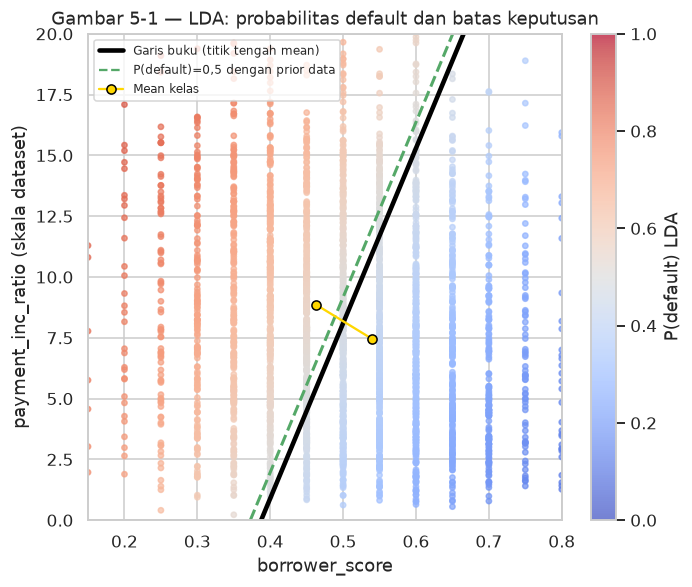

Proporsi diprediksi default (cutoff 0,5): 0.4573


In [7]:
display(pd.DataFrame(loan_lda.scalings_, index=lda_predictors, columns=["LD1 (bobot diskriminan)"]))
lda_proba = pd.DataFrame(loan_lda.predict_proba(X_lda), columns=loan_lda.classes_)
display(lda_proba.head())
assert np.isclose(loan_lda.scalings_[0, 0], 7.1758, atol=5e-3) and np.isclose(lda_proba.loc[0, "default"], 0.5535, atol=1e-3)

center = loan_lda.means_.mean(axis=0)
slope = -loan_lda.scalings_[0, 0] / loan_lda.scalings_[1, 0]
intercept = center[1] - center[0] * slope
xg, yg = np.meshgrid(np.linspace(0.15, 0.8, 300), np.linspace(0, 20, 300))
grid_lda = pd.DataFrame({"borrower_score": xg.ravel(), "payment_inc_ratio": yg.ravel()})
p_grid = loan_lda.predict_proba(grid_lda)[:, list(loan_lda.classes_).index("default")].reshape(xg.shape)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
points = ax.scatter(X_lda.borrower_score, X_lda.payment_inc_ratio, c=lda_proba["default"], cmap="coolwarm",
                    s=12, alpha=.7, vmin=0, vmax=1)
ax.plot([(0 - intercept) / slope, (20 - intercept) / slope], [0, 20], lw=3, color="black",
        label="Garis buku (titik tengah mean)")
ax.contour(xg, yg, p_grid, levels=[0.5], colors="C2", linestyles="--", linewidths=2)
ax.plot([], [], "C2--", label="P(default)=0,5 dengan prior data")
ax.plot(*loan_lda.means_.T, "o-", color="gold", mec="black", label="Mean kelas")
ax.set(xlim=(0.15, 0.8), ylim=(0, 20), xlabel="borrower_score", ylabel="payment_inc_ratio (skala dataset)",
       title="Gambar 5-1 — LDA: probabilitas default dan batas keputusan")
fig.colorbar(points, ax=ax, label="P(default) LDA")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()
print("Proporsi diprediksi default (cutoff 0,5):", round((lda_proba["default"] > .5).mean(), 4))

**Interpretasi dan catatan belajar.** Bobot `borrower_score` ≈7,18 dan `payment_inc_ratio` ≈−0,0997 sama dengan output buku. Perbedaan besar bobot sebagian karena skala: skor bergerak 0–1, sedangkan rasio pembayaran bergerak puluhan unit. Record di kiri-atas (skor rendah, rasio pembayaran tinggi) mendapat probabilitas default lebih besar. Garis hampir tegak menunjukkan pemisahan terutama ditentukan oleh skor peminjam. Karena prior default sedikit di bawah 0,5, batas berprior sedikit bergeser dari garis titik tengah.

<a id="c5-09"></a>
## Logistic Regression

*Acuan: cetak 208; PDF 226. Jenis: Teori.*

Regresi logistik mirip regresi linear berganda, tetapi targetnya biner. Model ini termasuk pendekatan **terstruktur**: probabilitas kelas dihubungkan dengan kombinasi linear prediktor melalui transformasi tertentu. Kelebihannya: cepat dihitung, koefisien dapat ditafsirkan, dan skor untuk data baru mudah dihitung sehingga populer dalam praktik.

Istilah kunci: **logit** (fungsi yang memetakan probabilitas 0–1 ke rentang ±∞), **odds** (rasio peluang sukses terhadap gagal), dan **log odds** (respons model yang dibuat linear terhadap prediktor).

<a id="c5-10"></a>
## Logistic Response Function and Logit

*Acuan: cetak 208; PDF 226. Jenis: Reproduksi Python buku.*

Memodelkan probabilitas langsung sebagai fungsi linear dapat menghasilkan nilai di luar 0–1. Regresi logistik memakai **logistic response function**:

$$p=\frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_qx_q)}}$$

**Odds** didefinisikan sebagai $\text{Odds}(Y=1)=p/(1-p)$; sebaliknya $p=\text{Odds}/(1+\text{Odds})$. Menggabungkan keduanya:

$$\log(\text{Odds}(Y=1))=\beta_0+\beta_1x_1+\cdots+\beta_qx_q$$

Fungsi log-odds atau **logit** memetakan $p\in(0,1)$ ke seluruh garis bilangan real, sehingga sisi kanan boleh bernilai berapa pun. Kelas diprediksi dengan cutoff probabilitas, umumnya 0,5.

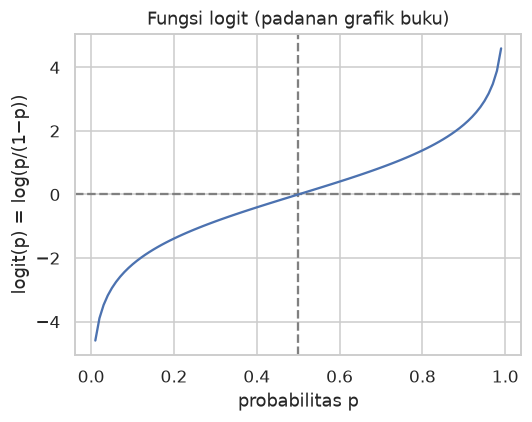

,p,logit,odds
0,0.01,-4.5951,0.0101
9,0.10,-2.1972,0.1111
49,0.50,0.0000,1.0000
89,0.90,2.1972,9.0000
98,0.99,4.5951,99.0000


In [8]:
p = np.arange(0.01, 1, 0.01)
logit_df = pd.DataFrame({"p": p, "logit": np.log(p / (1 - p)), "odds": p / (1 - p)})
fig, ax = plt.subplots(figsize=(5, 4))
ax.axhline(0, color="grey", ls="--"); ax.axvline(0.5, color="grey", ls="--")
ax.plot(logit_df.p, logit_df.logit)
ax.set(xlabel="probabilitas p", ylabel="logit(p) = log(p/(1−p))", title="Fungsi logit (padanan grafik buku)")
plt.tight_layout(); plt.show()
display(logit_df.iloc[[0, 9, 49, 89, 98]].round(4))

**Interpretasi dan catatan belajar.** Logit bernilai nol pada p=0,5 (odds 1), negatif saat p<0,5, positif saat p>0,5, dan menuju ±∞ di dekat 0 atau 1. Perubahan probabilitas yang sama, misalnya +0,01, menghasilkan perubahan logit yang jauh lebih besar di ujung kurva daripada di tengah.

<a id="c5-11"></a>
## Logistic Regression and the GLM

*Acuan: cetak 210; PDF 228. Jenis: Reproduksi Python dengan target 0/1 eksplisit.*

Contoh buku memprediksi `outcome` dari `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, dan `borrower_score`. Variabel kategori dikodekan reference coding (`drop_first=True`): level pertama secara alfabet menjadi baseline, yaitu `credit_card`, `MORTGAGE`, dan `< 1 Year`, sama seperti R.

**Catatan adaptasi:**
1. Kode buku memberi label string ke scikit-learn. Kelas diurutkan alfabet (`default`, `paid off`), sehingga model memodelkan peluang **paid off** dan semua tanda koefisien terbalik dari R. Notebook ini memakai target eksplisit `y=1` untuk default agar tanda sama dengan buku/R; versi label string ditampilkan sebagai pembanding.
2. `penalty='l2', C=1e42, solver='liblinear'` pada kode buku dimaksudkan sebagai regresi tanpa penalti. Pada scikit-learn 1.9 argumen `penalty` sudah deprecated, dan liblinear juga mempenalti intercept. Notebook memakai `C=np.inf` dengan solver `newton-cholesky`, yaitu maximum likelihood tanpa penalti seperti `glm` R.

In [9]:
logit_predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_", "borrower_score"]
X_logit = pd.get_dummies(loan_data[logit_predictors], prefix="", prefix_sep="", drop_first=True, dtype=int)
X_logit.columns = X_logit.columns.str.strip()
y_logit = loan_data["y"]
logit_reg = unpenalized_logit().fit(X_logit, y_logit)
coef_logit = pd.Series([logit_reg.intercept_[0], *logit_reg.coef_[0]], index=["intercept", *X_logit.columns])

book_style = unpenalized_logit().fit(X_logit, loan_data["outcome"].astype(str))
print("classes_ dengan label string:", book_style.classes_, "→ koefisien memodelkan P(", book_style.classes_[1], ")")
display(pd.DataFrame({"model P(default) [dipakai]": coef_logit,
                      "pola kode buku: P(paid off)": [book_style.intercept_[0], *book_style.coef_[0]]}).round(5))
np.testing.assert_allclose(coef_logit.to_numpy(), -np.r_[book_style.intercept_, book_style.coef_[0]], rtol=1e-4, atol=1e-6)
print("Baseline kategori:", {c: sorted(loan_data[c].unique())[0].strip() for c in ["purpose_", "home_", "emp_len_"]})
assert np.isclose(coef_logit["borrower_score"], -4.6126, atol=1e-3) and np.isclose(coef_logit["intercept"], 1.6381, atol=1e-3)

classes_ dengan label string: ['default' 'paid off'] → koefisien memodelkan P( paid off )


,model P(default) [dipakai],pola kode buku: P(paid off)
intercept,1.63809,-1.63809
payment_inc_ratio,0.07974,-0.07974
borrower_score,-4.61262,4.61262
debt_consolidation,0.24937,-0.24937
home_improvement,0.40774,-0.40774
major_purchase,0.22963,-0.22963
medical,0.51048,-0.51048
other,0.62066,-0.62066
small_business,1.21525,-1.21525
OWN,0.04833,-0.04833


Baseline kategori: {'purpose_': 'credit_card', 'home_': 'MORTGAGE', 'emp_len_': '< 1 Year'}


**Interpretasi dan catatan belajar.** Koefisien model P(default) sama dengan output R buku: intercept ≈1,638, `payment_inc_ratio` ≈0,080, `borrower_score` ≈−4,613, dan `small_business` ≈1,215. Kolom kanan memperlihatkan bahwa koefisien hanya berganti tanda ketika kelas yang dimodelkan ditukar; prediksinya identik. Selalu periksa `classes_` sebelum menafsirkan tanda koefisien.

<a id="c5-12"></a>
## Generalized Linear Models

*Acuan: cetak 212; PDF 230. Jenis: Teori.*

GLM ditentukan oleh dua komponen utama:

- **Distribusi/keluarga probabilitas** untuk target, misalnya binomial untuk respons biner, Poisson untuk hitungan, gamma untuk waktu atau nilai positif yang miring.
- **Link function** yang menghubungkan mean respons dengan prediktor linear $\beta_0+\sum\beta_jx_j$, misalnya logit untuk binomial dan log untuk Poisson.

Regresi logistik adalah GLM dengan keluarga binomial dan link logit. Regresi linear biasa adalah GLM dengan keluarga Gaussian dan link identitas. Keluarga lain yang disebut buku antara lain Poisson (sering diganti negative binomial bila terjadi overdispersion), gamma, dan inverse Gaussian. Model biner sering disebut **logistic regression**, sedangkan istilah GLM dipakai untuk kerangka umumnya.

<a id="c5-13"></a>
## Predicted Values from Logistic Regression

*Acuan: cetak 212; PDF 230. Jenis: Reproduksi Python buku.*

Prediksi mentah regresi logistik berada pada skala log-odds: $\hat Y=\log(\text{Odds}(Y=1))$. Probabilitas diperoleh dengan fungsi logistik $\hat p=1/(1+e^{-\hat Y})$. Buku menampilkan ringkasan kedua skala untuk data latih. Kelas diprediksi default bila $\hat p>0{,}5$; cutoff ini dapat diubah sesuai biaya kesalahan.

In [10]:
log_odds = logit_reg.decision_function(X_logit)
p_default = logit_reg.predict_proba(X_logit)[:, 1]
np.testing.assert_allclose(p_default, 1 / (1 + np.exp(-log_odds)), rtol=1e-10)
display(pd.DataFrame({"log-odds default": log_odds, "P(default)": p_default}).describe().round(4))
print("Proporsi diprediksi default pada cutoff 0,5:", round((p_default > 0.5).mean(), 4))

,log-odds default,P(default)
count,45342.0000,45342.0000
mean,0.0026,0.5000
std,0.7489,0.1674
min,-2.7048,0.0627
25%,-0.5188,0.3731
50%,-0.0085,0.4979
75%,0.5051,0.6236
max,3.5096,0.9710


Proporsi diprediksi default pada cutoff 0,5: 0.4959


**Interpretasi dan catatan belajar.** Probabilitas default berkisar sekitar 0,06–0,97 dengan median ≈0,50; rentangnya cocok dengan output buku. Rata-rata probabilitas tepat 0,5 karena regresi logistik maximum likelihood dengan intercept membuat rata-rata prediksi sama dengan proporsi kelas pada data latih, dan data ini seimbang. Rata-rata yang tepat tidak berarti setiap prediksi individual akurat.

<a id="c5-14"></a>
## Interpreting the Coefficients and Odds Ratios

*Acuan: cetak 213; PDF 231. Jenis: Reproduksi grafik buku + tabel odds ratio tambahan.*

**Odds ratio** membandingkan odds pada dua kondisi: $\text{OR}=\text{Odds}(Y=1\mid X=1)/\text{Odds}(Y=1\mid X=0)$. Untuk variabel dummy, $e^{\beta_j}$ adalah odds ratio kategori itu terhadap baseline dengan prediktor lain tetap. Untuk variabel numerik, $e^{\beta_j}$ adalah faktor pengali odds untuk kenaikan satu unit. Koefisien regresi logistik sendiri adalah log odds ratio.

Odds ratio lebih mudah dimanipulasi secara matematis daripada rasio probabilitas, tetapi tidak sama dengan "kali lipat peluang": perubahan probabilitas sebenarnya bergantung pada nilai awal. **Tambahan:** tabel memakai GLM `statsmodels` untuk interval kepercayaan 95% odds ratio (Wald).

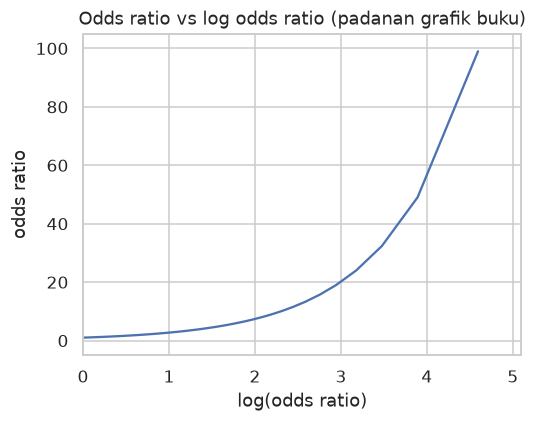

,koefisien (log OR),odds ratio,"OR 2,5%","OR 97,5%"
payment_inc_ratio,0.0797,1.0830,1.0777,1.0883
borrower_score,-4.6126,0.0099,0.0084,0.0117
debt_consolidation,0.2494,1.2832,1.2156,1.3546
home_improvement,0.4077,1.5034,1.3722,1.6472
major_purchase,0.2296,1.2581,1.1325,1.3977
medical,0.5105,1.6661,1.4055,1.9750
other,0.6207,1.8602,1.7218,2.0096
small_business,1.2153,3.3712,2.9777,3.8166
OWN,0.0483,1.0495,0.9741,1.1307
RENT,0.1573,1.1704,1.1227,1.2200


Kenaikan borrower_score 0,1 mengalikan odds default dengan 0.6305


In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(logit_df.logit, logit_df.odds)
ax.set(xlabel="log(odds ratio)", ylabel="odds ratio", xlim=(0, 5.1), ylim=(-5, 105),
       title="Odds ratio vs log odds ratio (padanan grafik buku)")
plt.tight_layout(); plt.show()

logit_glm = sm.GLM(y_logit, sm.add_constant(X_logit.astype(float)), family=sm.families.Binomial()).fit()
np.testing.assert_allclose(logit_glm.params.to_numpy(), coef_logit.to_numpy(), rtol=1e-4, atol=1e-6)
or_table = pd.DataFrame({"koefisien (log OR)": logit_glm.params, "odds ratio": np.exp(logit_glm.params),
                         "OR 2,5%": np.exp(logit_glm.conf_int()[0]), "OR 97,5%": np.exp(logit_glm.conf_int()[1])})
display(or_table.drop(index="const").round(4))
print("Kenaikan borrower_score 0,1 mengalikan odds default dengan", round(np.exp(0.1 * coef_logit["borrower_score"]), 4))

**Interpretasi dan catatan belajar.** `small_business` memiliki odds ratio ≈3,37: pada nilai prediktor lain yang sama, odds default pinjaman usaha kecil sekitar 3,4 kali odds pinjaman `credit_card`. Kenaikan satu unit `payment_inc_ratio` mengalikan odds dengan ≈1,083. Karena `borrower_score` hanya berskala 0–1, odds ratio per satu unit (≈0,01) terlalu ekstrem untuk dibaca; per kenaikan 0,1 odds dikalikan ≈0,63. Interval `OWN` mencakup 1, jadi data ini tidak memberi bukti kuat perbedaan odds `OWN` dibanding `MORTGAGE`. Semua tafsiran adalah asosiasi kondisional pada data seimbang, bukan efek kausal.

<a id="c5-15"></a>
## Linear and Logistic Regression: Similarities and Differences

*Acuan: cetak 214; PDF 232. Jenis: Teori + pembanding tambahan.*

Persamaannya: keduanya memakai prediktor linear $\beta_0+\sum\beta_jx_j$, kode kategori yang sama, dan banyak alat diagnostik yang mirip. Perbedaannya:

- **Cara fit.** Regresi linear memakai least squares dengan solusi tertutup. Regresi logistik tidak memiliki solusi tertutup; parameternya dicari dengan **maximum likelihood estimation (MLE)**, yaitu parameter yang membuat data teramati paling mungkin muncul. Algoritmenya iteratif (misalnya Fisher scoring/IRLS) karena likelihood bergantung nonlinear pada parameter.
- **Ukuran kecocokan.** Regresi logistik memakai **deviance** $=-2(\log L_{model}-\log L_{saturated})$; untuk respons biner individual $\log L_{saturated}=0$. Deviance lebih kecil berarti fit lebih baik.
- **Residual dan prediksi.** Target hanya 0/1, sehingga residual tidak tersebar normal dan prediksi linear langsung (linear probability model) bisa keluar dari 0–1.

**Tambahan:** sel berikut menghitung log-likelihood Bernoulli secara manual dan membandingkan model logistik dengan regresi linear pada target 0/1.

In [12]:
loglik_manual = np.sum(y_logit * np.log(p_default) + (1 - y_logit) * np.log(1 - p_default))
print(f"log-likelihood manual = {loglik_manual:.3f}; statsmodels = {logit_glm.llf:.3f}; "
      f"deviance = −2 logL = {-2 * loglik_manual:.3f}; statsmodels deviance = {logit_glm.deviance:.3f}")
np.testing.assert_allclose([loglik_manual, -2 * loglik_manual], [logit_glm.llf, logit_glm.deviance], rtol=1e-8)

lpm = sm.OLS(y_logit, sm.add_constant(X_logit.astype(float))).fit()
compare_lpm = pd.DataFrame({
    "prediksi minimum": [lpm.fittedvalues.min(), p_default.min()],
    "prediksi maksimum": [lpm.fittedvalues.max(), p_default.max()],
    "jumlah prediksi di luar [0,1]": [int(((lpm.fittedvalues < 0) | (lpm.fittedvalues > 1)).sum()), 0],
    "AUC in-sample": [roc_auc_score(y_logit, lpm.fittedvalues), roc_auc_score(y_logit, p_default)],
}, index=["Regresi linear (target 0/1)", "Regresi logistik (MLE)"])
display(compare_lpm.round(4))

log-likelihood manual = -28757.402; statsmodels = -28757.402; deviance = −2 logL = 57514.804; statsmodels deviance = 57514.804


,prediksi minimum,prediksi maksimum,"jumlah prediksi di luar [0,1]",AUC in-sample
Regresi linear (target 0/1),-0.1043,1.2743,98,0.6917
Regresi logistik (MLE),0.0627,0.9710,0,0.6917


**Interpretasi dan catatan belajar.** Deviance GLM persis −2 kali log-likelihood Bernoulli, sesuai definisi untuk respons biner. Regresi linear pada target 0/1 memberi peringkat yang hampir sama (AUC mirip) tetapi sebagian prediksinya keluar dari rentang probabilitas; regresi logistik selalu berada di 0–1 dan memiliki tafsiran odds yang konsisten.

<a id="c5-16"></a>
## Assessing the Model

*Acuan: cetak 216; PDF 234. Jenis: Reproduksi Python buku; partial residual memakai working residual.*

Seperti regresi linear, ringkasan GLM memberi standard error, statistik z, dan p-value. Buku menekankan p-value dipakai sebagai **indikator relatif kepentingan** prediktor, bukan uji signifikansi formal setelah eksplorasi. Model logistik tidak memiliki RMSE atau R² yang setara; yang dipakai antara lain deviance, AIC, dan metrik klasifikasi. Seleksi stepwise, interaksi, dan spline juga dapat diterapkan.

Contoh buku menambahkan spline: `bs(payment_inc_ratio, df=8)` dan `bs(borrower_score, df=3)`, lalu memeriksa partial residual. **Adaptasi:** fungsi partial residual pada kode Python buku mengodekan target secara terbalik; notebook memakai definisi standar GLM, $r^{partial}=r^{working}+\hat f_j(x_j)$ dengan $r^{working}=(y-\hat p)/[\hat p(1-\hat p)]$ (seperti `termplot` R), sehingga titik di atas kurva berasal dari default.

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Mon, 19 Oct 2026   Deviance:                       57515.
Time:                        17:42:07   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.6381      0

,model,parameter,deviance,AIC
0,Linear pada logit,12,57514.80,57538.80
1,Dengan spline,21,57462.28,57504.28


Tambahan uji likelihood-ratio: penurunan deviance 52.53 dengan df=9, p=3.59e-08


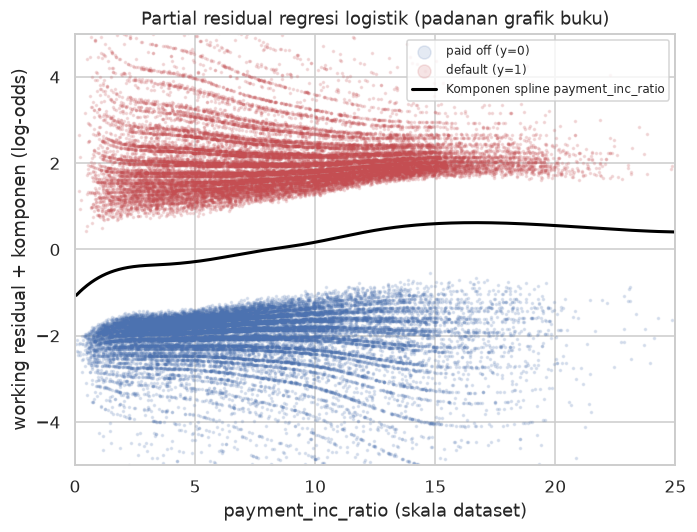

Persentase titik di luar sumbu-y ±5: 0.81 %


In [13]:
print(logit_glm.summary())
spline_glm = smf.glm("y ~ bs(payment_inc_ratio, df=8) + purpose_ + home_ + emp_len_ + bs(borrower_score, df=3)",
                     data=loan_data, family=sm.families.Binomial()).fit()
fit_table = pd.DataFrame([
    {"model": "Linear pada logit", "parameter": len(logit_glm.params), "deviance": logit_glm.deviance, "AIC": logit_glm.aic},
    {"model": "Dengan spline", "parameter": len(spline_glm.params), "deviance": spline_glm.deviance, "AIC": spline_glm.aic}])
display(fit_table.round(2))
lr_stat = logit_glm.deviance - spline_glm.deviance
lr_df = len(spline_glm.params) - len(logit_glm.params)
print(f"Tambahan uji likelihood-ratio: penurunan deviance {lr_stat:.2f} dengan df={lr_df}, p={stats.chi2.sf(lr_stat, lr_df):.2e}")

names = spline_glm.model.exog_names
spline_cols = [i for i, n in enumerate(names) if n.startswith("bs(payment_inc_ratio")]
component = spline_glm.model.exog[:, spline_cols] @ spline_glm.params.iloc[spline_cols].to_numpy()
component = component - component.mean()
partial = spline_glm.resid_working + component
x_pir = loan_data.payment_inc_ratio.to_numpy(); order = np.argsort(x_pir)
fig, ax = plt.subplots(figsize=(6.5, 5))
for label, mask, color in [("paid off (y=0)", y_logit == 0, "C0"), ("default (y=1)", y_logit == 1, "C3")]:
    ax.scatter(x_pir[mask], partial[mask], s=2, alpha=.15, color=color, label=label)
ax.plot(x_pir[order], component[order], color="black", lw=2, label="Komponen spline payment_inc_ratio")
ax.set(xlim=(0, 25), ylim=(-5, 5), xlabel="payment_inc_ratio (skala dataset)",
       ylabel="working residual + komponen (log-odds)", title="Partial residual regresi logistik (padanan grafik buku)")
ax.legend(markerscale=6, fontsize=8); plt.tight_layout(); plt.show()
print("Persentase titik di luar sumbu-y ±5:", round(100 * (np.abs(partial) > 5).mean(), 2), "%")

**Interpretasi dan catatan belajar.** Semua prediktor kecuali `OWN` memiliki |z| besar, konsisten dengan interval odds ratio sebelumnya. Model spline menurunkan deviance ≈52,5 dengan 9 parameter tambahan (uji likelihood-ratio p≈3,6×10⁻⁸) dan AIC turun ≈34 poin. Dengan 45 ribu record, perbaikan kecil pun mudah "signifikan"; ini metrik in-sample dan belum tentu terasa pada akurasi klasifikasi. Partial residual logistik membentuk dua "awan": atas berasal dari default dan bawah dari paid off, karena target hanya 0/1. Kurva komponen naik lalu mendatar pada rasio besar; plot ini kurang informatif dibanding versi regresi linear dan terutama berguna untuk melihat bentuk nonlinear kasar.

<a id="c5-17"></a>
## Evaluating Classification Models

*Acuan: cetak 219; PDF 237. Jenis: Teori + holdout tambahan.*

Model klasifikasi umumnya menghasilkan skor/probabilitas, lalu cutoff mengubahnya menjadi kelas. **Accuracy** adalah proporsi prediksi benar: $(TP+TN)/n$. Evaluasi yang jujur memakai data yang tidak dipakai untuk fit (holdout atau cross-validation), seperti pada Bab 4.

Istilah kunci bab ini: accuracy, confusion matrix, sensitivity/recall, specificity, precision, ROC curve, dan lift. Buku menghitung metrik berikutnya pada data latih untuk menjelaskan definisi. **Tambahan:** holdout stratified 30% berikut memperlihatkan selisih skor latih dan uji. Catatan leakage: `borrower_score` dibuat dengan KNN yang melihat outcome seluruh `loan_data`, termasuk record uji, sehingga skor holdout ini pun masih bisa optimistis (dianalisis di Bab 6).

In [14]:
train_idx, test_idx = train_test_split(loan_data.index, test_size=0.3, random_state=SEED, stratify=y_logit)
holdout_model = unpenalized_logit().fit(X_logit.loc[train_idx], y_logit.loc[train_idx])
p_test = holdout_model.predict_proba(X_logit.loc[test_idx])[:, 1]
y_test = y_logit.loc[test_idx]
eval_table = pd.DataFrame([
    {"evaluasi": "In-sample seluruh data (cara buku)", "n": len(y_logit),
     "accuracy": accuracy_score(y_logit, p_default > .5), "AUC": roc_auc_score(y_logit, p_default)},
    {"evaluasi": "Train 70%", "n": len(train_idx),
     "accuracy": accuracy_score(y_logit.loc[train_idx], holdout_model.predict(X_logit.loc[train_idx])),
     "AUC": roc_auc_score(y_logit.loc[train_idx], holdout_model.predict_proba(X_logit.loc[train_idx])[:, 1])},
    {"evaluasi": "Holdout 30% (tambahan)", "n": len(test_idx),
     "accuracy": accuracy_score(y_test, p_test > .5), "AUC": roc_auc_score(y_test, p_test)}])
display(eval_table.round(4))

,evaluasi,n,accuracy,AUC
0,In-sample seluruh data (cara buku),45342,0.6365,0.6917
1,Train 70%,31739,0.6371,0.6925
2,Holdout 30% (tambahan),13603,0.6351,0.6895


**Interpretasi dan catatan belajar.** Model logistik dengan 12 parameter dan 45 ribu record hampir tidak overfit: accuracy dan AUC holdout dekat dengan nilai latih. Untuk model fleksibel di Bab 6 selisih ini bisa jauh lebih besar. Accuracy sekitar 64% pada data seimbang hanya sedikit di atas tebakan 50%, jadi pemisahan kelas memang terbatas.

<a id="c5-18"></a>
## Confusion Matrix

*Acuan: cetak 221; PDF 239. Jenis: Reproduksi Python buku.*

Confusion matrix menabulasi kelas aktual terhadap kelas prediksi. Mengikuti buku, baris adalah kelas aktual, kolom adalah prediksi, dan kelas positif (default) diletakkan pertama:

| | Ŷ = default | Ŷ = paid off |
|---|---|---|
| **Y = default** | TP (true positive) | FN (false negative) |
| **Y = paid off** | FP (false positive) | TN (true negative) |

Diagonal berisi prediksi benar. Konvensi tata letak berbeda antar-software (misalnya `confusion_matrix` scikit-learn mengurutkan label secara default), jadi selalu tentukan urutan label secara eksplisit.

,Ŷ = default,Ŷ = paid off
Y = default,14336,8335
Y = paid off,8148,14523


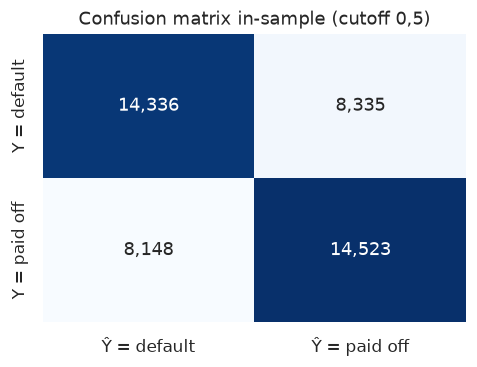

Accuracy: 0.6365


In [15]:
pred_default = p_default > 0.5
true_default = y_logit == 1
conf_mat = pd.DataFrame([[np.sum(true_default & pred_default), np.sum(true_default & ~pred_default)],
                         [np.sum(~true_default & pred_default), np.sum(~true_default & ~pred_default)]],
                        index=["Y = default", "Y = paid off"], columns=["Ŷ = default", "Ŷ = paid off"])
display(conf_mat)
np.testing.assert_array_equal(conf_mat.to_numpy(), confusion_matrix(y_logit, pred_default.astype(int), labels=[1, 0]))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(conf_mat, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Confusion matrix in-sample (cutoff 0,5)"); plt.tight_layout(); plt.show()
print("Accuracy:", round(np.trace(conf_mat.to_numpy()) / conf_mat.to_numpy().sum(), 4))

**Interpretasi dan catatan belajar.** Dari 22.671 default, sekitar 14,3 ribu terdeteksi dan 8,3 ribu terlewat (FN); dari 22.671 paid off, sekitar 8,1 ribu salah ditandai default (FP). Angka berbeda satu unit dari output Python resmi karena solver berbeda (liblinear vs newton-cholesky), bukan karena data berbeda.

<a id="c5-19"></a>
## The Rare Class Problem

*Acuan: cetak 223; PDF 241. Jenis: Teori + demonstrasi tambahan.*

Pada banyak masalah, kelas yang penting justru langka: penipuan, default, pelanggan yang membeli. Classifier yang selalu memprediksi kelas mayoritas bisa memiliki accuracy tinggi tetapi tidak berguna. Biaya kesalahan juga sering tidak simetris: melewatkan satu default (FN) bisa lebih mahal daripada menolak satu pinjaman baik (FP), sehingga model yang "lebih tidak akurat" tetapi menangkap lebih banyak kelas langka bisa lebih bernilai.

**Tambahan:** baseline "selalu paid off" pada `full_train_set` yang tidak seimbang.

In [16]:
always_paid = np.zeros(len(full_train_set), dtype=int)
print(f"Proporsi default full_train_set: {full_train_set.y.mean():.4f}")
print(f"Accuracy baseline 'selalu paid off': {accuracy_score(full_train_set.y, always_paid):.4f}")
print(f"Default yang tertangkap (recall): {np.sum((always_paid == 1) & (full_train_set.y == 1))} dari {full_train_set.y.sum():,}")

Proporsi default full_train_set: 0.1889
Accuracy baseline 'selalu paid off': 0.8111
Default yang tertangkap (recall): 0 dari 22,671


**Interpretasi dan catatan belajar.** Baseline tanpa informasi apa pun mencapai accuracy ≈81%, jauh di atas 64% model logistik pada data seimbang, tetapi tidak menangkap satu pun default. Karena itu accuracy harus selalu dibandingkan dengan baseline kelas mayoritas dan dilengkapi metrik per kelas.

<a id="c5-20"></a>
## Precision, Recall, and Specificity

*Acuan: cetak 223; PDF 241. Jenis: Reproduksi Python buku.*

- **Precision** $=TP/(TP+FP)$: dari semua yang diprediksi default, berapa yang benar default.
- **Recall/sensitivity** $=TP/(TP+FN)$: dari semua default sebenarnya, berapa yang tertangkap.
- **Specificity** $=TN/(TN+FP)$: dari semua paid off sebenarnya, berapa yang benar diprediksi paid off.

Recall dan specificity saling tarik-menarik ketika cutoff digeser. **Tambahan:** F1 $=2\cdot\text{precision}\cdot\text{recall}/(\text{precision}+\text{recall})$ dari `precision_recall_fscore_support`.

In [17]:
cm = conf_mat.to_numpy()
metrics_manual = pd.Series({"precision": cm[0, 0] / cm[:, 0].sum(), "recall": cm[0, 0] / cm[0, :].sum(),
                            "specificity": cm[1, 1] / cm[1, :].sum()})
display(metrics_manual.round(4).to_frame("nilai (kelas positif = default)"))
prec, rec, f1, support = precision_recall_fscore_support(y_logit, pred_default.astype(int), labels=[1, 0])
display(pd.DataFrame({"precision": prec, "recall": rec, "F1": f1, "support": support},
                     index=["default (1)", "paid off (0)"]).round(4))
np.testing.assert_allclose([prec[0], rec[0], rec[1]], metrics_manual.to_numpy())

,nilai (kelas positif = default)
precision,0.6376
recall,0.6323
specificity,0.6406


,precision,recall,F1,support
default (1),0.6376,0.6323,0.635,22671
paid off (0),0.6354,0.6406,0.638,22671


**Interpretasi dan catatan belajar.** Precision, recall, dan specificity sama-sama sekitar 0,63–0,64. Recall kelas paid off pada tabel scikit-learn sama dengan specificity untuk kelas default; ini cara cepat memeriksa definisi. Nilai yang seimbang wajar karena kelas seimbang dan cutoff 0,5.

<a id="c5-21"></a>
## ROC Curve

*Acuan: cetak 224; PDF 242. Jenis: Reproduksi Python buku + titik cutoff tambahan.*

Kurva **ROC** (receiver operating characteristic) memplot recall terhadap specificity untuk semua cutoff. Algoritmenya: urutkan record berdasarkan probabilitas kelas positif, lalu untuk setiap cutoff hitung recall dan specificity kumulatif. Mengikuti buku, sumbu-x adalah specificity dari 1 ke 0 (setara false positive rate 0 ke 1). Classifier acak berada di diagonal; kurva yang menempel ke kiri-atas menunjukkan pemisahan lebih baik.

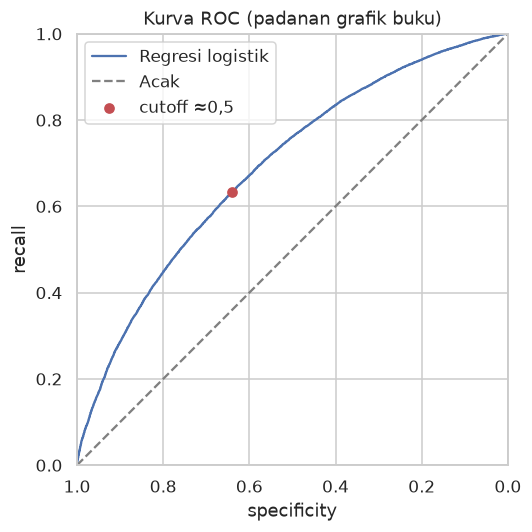

,recall,specificity,cutoff
1,0.0000,1.0000,0.9710
4063,0.3285,0.8771,0.6374
8125,0.5402,0.7271,0.5427
12187,0.7225,0.5471,0.4562
16249,0.8748,0.3318,0.3614
20311,1.0000,0.0000,0.0627


In [18]:
fpr, tpr, thresholds = roc_curve(y_logit, p_default)
roc_df = pd.DataFrame({"recall": tpr, "specificity": 1 - fpr, "cutoff": thresholds})
point = roc_df.iloc[(roc_df.cutoff - 0.5).abs().argmin()]
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(roc_df.specificity, roc_df.recall, label="Regresi logistik")
ax.plot((1, 0), (0, 1), color="grey", ls="--", label="Acak")
ax.scatter(point.specificity, point.recall, color="C3", zorder=3, label=f"cutoff ≈0,5")
ax.set(xlim=(1, 0), ylim=(0, 1), xlabel="specificity", ylabel="recall", title="Kurva ROC (padanan grafik buku)")
ax.legend(); plt.tight_layout(); plt.show()
display(roc_df.iloc[np.linspace(1, len(roc_df) - 1, 6).astype(int)].round(4))

**Interpretasi dan catatan belajar.** Titik merah adalah confusion matrix sebelumnya. Menaikkan recall ke sekitar 0,9 menuntut penurunan specificity yang besar: lebih banyak pinjaman baik ditandai berisiko. Bentuk kurva menggambarkan kemampuan ranking model, bukan satu keputusan cutoff.

<a id="c5-22"></a>
## AUC

*Acuan: cetak 226; PDF 244. Jenis: Reproduksi Python buku + holdout dan tafsiran probabilistik tambahan.*

**AUC** (area under the ROC curve) merangkum kurva ROC menjadi satu angka: 1 berarti pemisahan sempurna, 0,5 setara acak. AUC dapat dihitung dengan aturan trapesium pada titik ROC. Tafsiran setara: AUC adalah peluang record default yang dipilih acak mendapat skor lebih tinggi daripada record paid off yang dipilih acak (statistik Mann–Whitney). **Tambahan:** AUC holdout dan pemeriksaan tafsiran pasangan acak.

,AUC
rumus jumlah persegi panjang kode buku,0.6917
trapesium,0.6917
roc_auc_score,0.6917
200.000 pasangan acak,0.6914
holdout 30% (tambahan),0.6895


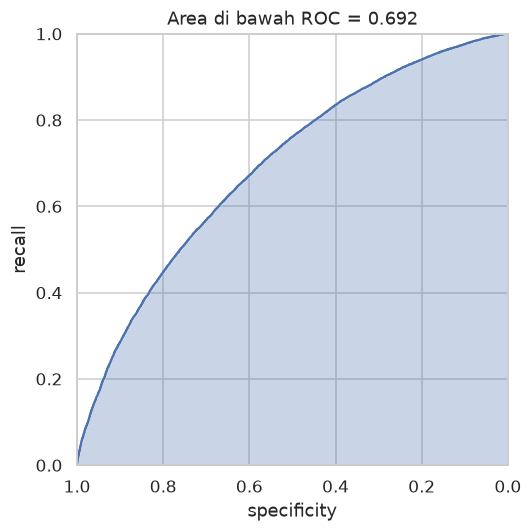

In [19]:
auc_book_formula = np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity))
auc_trapezoid = np.trapezoid(tpr, fpr)
auc_sklearn = roc_auc_score(y_logit, p_default)
rng = np.random.default_rng(SEED)
pos, neg = p_default[y_logit == 1], p_default[y_logit == 0]
i, j = rng.integers(0, len(pos), 200_000), rng.integers(0, len(neg), 200_000)
auc_pairs = np.mean(pos[i] > neg[j]) + 0.5 * np.mean(pos[i] == neg[j])
display(pd.Series({"rumus jumlah persegi panjang kode buku": auc_book_formula, "trapesium": auc_trapezoid,
                   "roc_auc_score": auc_sklearn, "200.000 pasangan acak": auc_pairs,
                   "holdout 30% (tambahan)": roc_auc_score(y_test, p_test)}).round(4).to_frame("AUC"))
assert np.isclose(auc_sklearn, 0.6917, atol=5e-4)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(roc_df.specificity, roc_df.recall)
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)
ax.set(xlim=(1, 0), ylim=(0, 1), xlabel="specificity", ylabel="recall", title=f"Area di bawah ROC = {auc_sklearn:.3f}")
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** AUC ≈0,69, sama dengan buku. Semua cara menghitung memberi angka yang sama (pasangan acak hanya berbeda karena sampling). Dalam bahasa sederhana: sekitar 69% pasangan default–paid off diurutkan benar oleh model. AUC tidak bergantung pada cutoff dan prior kelas, tetapi juga tidak memberi tahu biaya keputusan pada cutoff tertentu.

<a id="c5-23"></a>
## Lift

*Acuan: cetak 228; PDF 246. Jenis: Tambahan implementasi konsep buku (repository tidak menyediakan kode Python).*

**Lift** mengukur seberapa efektif model mengumpulkan kelas positif di urutan teratas. Urutkan record dari probabilitas default tertinggi, lalu bandingkan proporsi default pada desil teratas dengan proporsi default rata-rata. Lift 2 pada desil pertama berarti 10% record teratas berisi default dua kali lebih padat daripada memilih acak. **Cumulative gains** memperlihatkan persentase seluruh default yang tertangkap bila kita memeriksa x% record teratas. Lift berguna ketika kapasitas tindakan terbatas, misalnya hanya 10% pemohon yang bisa ditinjau manual. Perhitungan memakai holdout.

,n,default,p_mean,rate default,lift desil,% default tertangkap kumulatif
desil,,,,,,
1,1361,1051,0.787,0.772,1.544,15.451
2,1360,936,0.688,0.688,1.376,29.212
3,1360,859,0.628,0.632,1.263,41.841
4,1360,772,0.574,0.568,1.135,53.190
5,1361,700,0.525,0.514,1.029,63.481
6,1360,663,0.477,0.488,0.975,73.228
7,1360,580,0.429,0.426,0.853,81.755
8,1360,523,0.377,0.385,0.769,89.444
9,1360,437,0.317,0.321,0.643,95.869


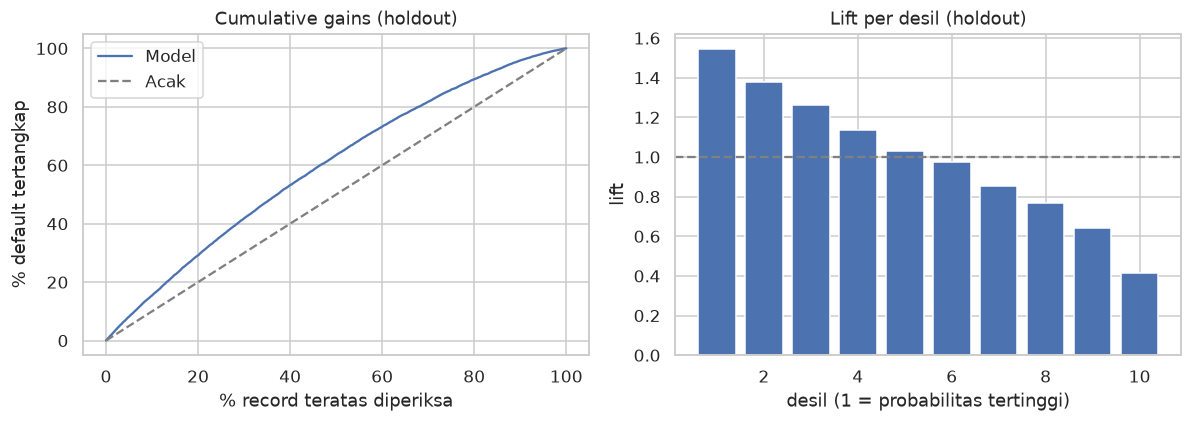

In [20]:
lift_df = pd.DataFrame({"y": y_test.to_numpy(), "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
lift_df["desil"] = pd.qcut(np.arange(len(lift_df)), 10, labels=range(1, 11))
base_rate = lift_df.y.mean()
decile = lift_df.groupby("desil", observed=True).agg(n=("y", "size"), default=("y", "sum"), p_mean=("p", "mean"))
decile["rate default"] = decile.default / decile.n
decile["lift desil"] = decile["rate default"] / base_rate
decile["% default tertangkap kumulatif"] = 100 * decile.default.cumsum() / lift_df.y.sum()
display(decile.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
frac = np.arange(1, len(lift_df) + 1) / len(lift_df)
axes[0].plot(100 * frac, 100 * lift_df.y.cumsum() / lift_df.y.sum(), label="Model")
axes[0].plot([0, 100], [0, 100], ls="--", color="grey", label="Acak")
axes[0].set(xlabel="% record teratas diperiksa", ylabel="% default tertangkap", title="Cumulative gains (holdout)")
axes[0].legend()
axes[1].bar(decile.index.astype(int), decile["lift desil"])
axes[1].axhline(1, ls="--", color="grey")
axes[1].set(xlabel="desil (1 = probabilitas tertinggi)", ylabel="lift", title="Lift per desil (holdout)")
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Desil teratas berisi default sekitar 1,54 kali lebih padat daripada rata-rata (77% vs 50%) dan menangkap ≈15% seluruh default; lift turun bertahap hingga ≈0,41 pada desil terbawah. Separuh record teratas menangkap ≈63% default. Pada data seimbang lift maksimum hanya 2 (jika 10% teratas semuanya default), jadi angka lift pada data berbeda prior tidak dapat dibandingkan langsung.

<a id="c5-24"></a>
## Strategies for Imbalanced Data

*Acuan: cetak 230; PDF 248. Jenis: Teori.*

Ketika kelas yang dicari jarang, model statistik cenderung menghasilkan probabilitas kecil untuk kelas itu dan cutoff 0,5 hampir tidak pernah terlewati. Strategi yang dibahas buku:

- **Undersampling/down-sampling**: memakai lebih sedikit record kelas mayoritas.
- **Oversampling/up-sampling**: memakai record kelas minoritas lebih sering (misalnya bootstrap).
- **Up-weight/down-weight**: memberi bobot lebih besar pada kelas minoritas dalam fungsi likelihood.
- **Data generation**: membuat record sintetis mirip kelas minoritas (SMOTE dan variannya, memakai K tetangga terdekat).
- **Cost-based classification**: memilih cutoff atau keputusan berdasarkan biaya/manfaat, bukan accuracy.

Prinsip penting: resampling hanya boleh dilakukan pada **data latih**. Data uji harus mempertahankan proporsi kelas yang realistis agar metrik mencerminkan kondisi penggunaan.

<a id="c5-25"></a>
## Undersampling

*Acuan: cetak 231; PDF 249. Jenis: Reproduksi Python buku + undersampling tambahan.*

Bila data kelas mayoritas sangat banyak, undersampling membuat data lebih seimbang dan lebih ringan dihitung; informasi yang hilang relatif kecil karena record mayoritas sering redundan. `loan_data` sendiri adalah contoh hasil undersampling dari data penuh.

Contoh buku memfit regresi logistik pada `full_train_set` (18,9% default) dengan prediktor `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, `dti`, `revol_bal`, `revol_util`. **Catatan adaptasi:** output notebook Python resmi (liblinear, C=1e42) melaporkan hanya 0,0175% prediksi default karena optimasi liblinear tidak konvergen baik pada `revol_bal` yang berskala besar. Fit maximum likelihood tanpa penalti di bawah memberi ≈0,39%, sesuai versi R buku (sekitar 1/47 dari proporsi default sebenarnya).

In [21]:
imb_predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_", "dti", "revol_bal", "revol_util"]
X_full = pd.get_dummies(full_train_set[imb_predictors], prefix="", prefix_sep="", drop_first=True, dtype=int).astype(float)
X_full.columns = X_full.columns.str.strip()
y_full = full_train_set["y"]
full_model = unpenalized_logit().fit(X_full, y_full)
p_full = full_model.predict_proba(X_full)[:, 1]
pct_actual, pct_pred = 100 * y_full.mean(), 100 * (p_full > 0.5).mean()
print(f"% default aktual = {pct_actual:.3f}; % diprediksi default = {pct_pred:.3f}; rasio = 1/{pct_actual / pct_pred:.1f}")
print(f"Rata-rata P(default) = {p_full.mean():.4f}; maksimum = {p_full.max():.4f}; "
      f"persentil 99 = {np.percentile(p_full, 99):.4f}")
assert np.isclose(pct_pred, 0.394, atol=0.01)

# Tambahan: undersampling sendiri dari full_train_set (seluruh default + paid off acak sebanyak default)
rng = np.random.default_rng(SEED)
idx_default = np.flatnonzero(y_full == 1)
idx_paid = rng.choice(np.flatnonzero(y_full == 0), size=len(idx_default), replace=False)
under_idx = np.r_[idx_default, idx_paid]
under_model = unpenalized_logit().fit(X_full.iloc[under_idx], y_full.iloc[under_idx])
print(f"Tambahan undersampling 1:1 → % data penuh diprediksi default = {100 * (under_model.predict(X_full) == 1).mean():.2f}")

% default aktual = 18.895; % diprediksi default = 0.394; rasio = 1/47.9
Rata-rata P(default) = 0.1889; maksimum = 0.8675; persentil 99 = 0.4480
Tambahan undersampling 1:1 → % data penuh diprediksi default = 42.69


**Interpretasi dan catatan belajar.** Walaupun 18,9% pinjaman default, model data penuh hanya memprediksi 0,39% default karena hampir tidak ada probabilitas di atas 0,5 (persentil 99 masih jauh di bawahnya). Rata-rata probabilitas tetap 0,189: modelnya terkalibrasi, yang salah adalah memakai cutoff 0,5 untuk kelas langka. Setelah undersampling 1:1, sekitar 43% data penuh diprediksi default; probabilitas dari model undersampling tidak lagi mewakili peluang sebenarnya sehingga perlu dikoreksi bila dipakai sebagai probabilitas.

<a id="c5-26"></a>
## Oversampling and Up/Down Weighting

*Acuan: cetak 232; PDF 250. Jenis: Reproduksi Python buku + perbandingan koefisien tambahan.*

Bila kelas minoritas sangat sedikit, undersampling membuang terlalu banyak informasi. Alternatifnya, oversampling minoritas (sampling dengan pengembalian) atau memberi **bobot**. Buku memberi bobot $1/p$ untuk default ($p$ = proporsi default) dan 1 untuk paid off, sehingga total bobot default kira-kira sama dengan jumlah seluruh record. Bobot ini setara dengan oversampling tanpa menggandakan baris.

**Tambahan:** dalam regresi logistik yang spesifikasinya memadai, pembobotan kelas terutama menggeser **intercept** sebesar sekitar $\log(w)$, sementara slope relatif stabil. Sel berikut memeriksanya.

In [22]:
default_wt = 1 / y_full.mean()
weights = np.where(y_full == 1, default_wt, 1.0)
weighted_model = unpenalized_logit().fit(X_full, y_full, sample_weight=weights)
pct_weighted = 100 * (weighted_model.predict(X_full) == 1).mean()
print(f"Bobot default = {default_wt:.4f}; % diprediksi default dengan bobot = {pct_weighted:.2f}")
coef_compare = pd.DataFrame({"tanpa bobot": np.r_[full_model.intercept_, full_model.coef_[0]],
                             "dengan bobot": np.r_[weighted_model.intercept_, weighted_model.coef_[0]]},
                            index=["intercept", *X_full.columns])
coef_compare["selisih"] = coef_compare["dengan bobot"] - coef_compare["tanpa bobot"]
display(coef_compare.round(5).head(8))
print(f"Selisih intercept = {coef_compare.loc['intercept', 'selisih']:.4f}; log(bobot) = {np.log(default_wt):.4f}")

Bobot default = 5.2925; % diprediksi default dengan bobot = 57.67


,tanpa bobot,dengan bobot,selisih
intercept,-3.04405,-1.38717,1.65688
payment_inc_ratio,0.07281,0.07432,0.00151
dti,0.02574,0.02478,-0.00096
revol_bal,-0.00000,-0.00000,0.00000
revol_util,0.01120,0.01115,-0.00005
debt_consolidation,0.25919,0.26534,0.00615
home_improvement,0.46960,0.46275,-0.00685
major_purchase,0.31430,0.30237,-0.01193


Selisih intercept = 1.6569; log(bobot) = 1.6663


**Interpretasi dan catatan belajar.** Dengan bobot ≈5,29, sekitar 58% pinjaman diprediksi default, sama dengan angka R yang dilaporkan buku. Kita berpindah dari terlalu sedikit ke cukup banyak prediksi default. Selisih intercept mendekati $\log(5{,}29)\approx1{,}67$ dan slope hanya berubah kecil, artinya pembobotan hampir setara dengan menggeser cutoff, bukan mempelajari pola baru.

<a id="c5-27"></a>
## Data Generation

*Acuan: cetak 233; PDF 251. Jenis: Reproduksi Python buku + evaluasi holdout tambahan.*

Variasi oversampling yang menghasilkan record baru, bukan sekadar menggandakan. **SMOTE** (Synthetic Minority Oversampling Technique): untuk record minoritas, pilih salah satu dari K tetangga terdekat minoritasnya, lalu buat titik sintetis pada garis di antara keduanya dengan bobot acak. **ADASYN** memusatkan pembuatan data pada wilayah minoritas yang sulit (lebih banyak tetangga mayoritas). Paket `imbalanced-learn` menyediakan keduanya; `random_state=1` ditambahkan agar hasil dapat diulang.

**Catatan:** SMOTE biasa memperlakukan dummy kategori sebagai angka sehingga menghasilkan nilai pecahan seperti 0,37 untuk kolom `RENT`. Untuk prediktor campuran, `SMOTENC` lebih tepat. **Tambahan:** semua strategi dievaluasi pada split holdout berproporsi asli, dengan resampling hanya pada data latih.

In [23]:
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_full, y_full)
smote_model = unpenalized_logit().fit(X_smote, y_smote)
X_adasyn, y_adasyn = ADASYN(random_state=SEED).fit_resample(X_full, y_full)
adasyn_model = unpenalized_logit().fit(X_adasyn, y_adasyn)
display(pd.DataFrame({
    "% default setelah resampling": [100 * y_smote.mean(), 100 * y_adasyn.mean()],
    "% data asli diprediksi default": [100 * (smote_model.predict(X_full) == 1).mean(),
                                         100 * (adasyn_model.predict(X_full) == 1).mean()]},
    index=["SMOTE", "ADASYN"]).round(2))
dummy_cols = [c for c in X_full.columns if c not in imb_predictors]
synthetic = X_smote.iloc[len(X_full):][dummy_cols]
print(f"Baris sintetis SMOTE: {len(synthetic):,}; dengan minimal satu dummy pecahan: "
      f"{100 * (synthetic % 1 != 0).any(axis=1).mean():.1f}%")

# Tambahan: evaluasi jujur — resampling hanya pada train, test mempertahankan 18,9% default
tr, te = train_test_split(np.arange(len(y_full)), test_size=0.3, random_state=SEED, stratify=y_full)
Xtr, ytr, Xte, yte = X_full.iloc[tr], y_full.iloc[tr], X_full.iloc[te], y_full.iloc[te]
rng = np.random.default_rng(SEED)
under = np.r_[np.flatnonzero(ytr == 1), rng.choice(np.flatnonzero(ytr == 0), (ytr == 1).sum(), replace=False)]
strategies = {
    "Tanpa penanganan": unpenalized_logit().fit(Xtr, ytr),
    "Undersampling 1:1": unpenalized_logit().fit(Xtr.iloc[under], ytr.iloc[under]),
    "Up-weight 1/p": unpenalized_logit().fit(Xtr, ytr, sample_weight=np.where(ytr == 1, 1 / ytr.mean(), 1)),
    "SMOTE": unpenalized_logit().fit(*SMOTE(random_state=SEED).fit_resample(Xtr, ytr)),
    "ADASYN": unpenalized_logit().fit(*ADASYN(random_state=SEED).fit_resample(Xtr, ytr)),
}
rows = []
for name, model in strategies.items():
    proba = model.predict_proba(Xte)[:, 1]; pred = (proba > 0.5).astype(int)
    prec, rec, _, _ = precision_recall_fscore_support(yte, pred, labels=[1], zero_division=0)
    rows.append({"strategi": name, "% diprediksi default": 100 * pred.mean(), "recall": rec[0],
                 "precision": prec[0], "accuracy": accuracy_score(yte, pred), "AUC": roc_auc_score(yte, proba),
                 "rata-rata P(default)": proba.mean()})
strategy_table = pd.DataFrame(rows).set_index("strategi")
display(strategy_table.round(4))

,% default setelah resampling,% data asli diprediksi default
SMOTE,50.00,42.46
ADASYN,48.56,38.90


Baris sintetis SMOTE: 74,645; dengan minimal satu dummy pecahan: 83.0%


,% diprediksi default,recall,precision,accuracy,AUC,rata-rata P(default)
strategi,,,,,,
Tanpa penanganan,0.4389,0.0106,0.4557,0.8107,0.6486,0.1889
Undersampling 1:1,42.4258,0.5970,0.2658,0.6124,0.6484,0.4780
Up-weight 1/p,57.4631,0.7331,0.2410,0.5135,0.6486,0.5265
SMOTE,42.3313,0.5962,0.2661,0.6131,0.6484,0.4758
ADASYN,38.5838,0.5605,0.2745,0.6370,0.6480,0.4660


**Interpretasi dan catatan belajar.** SMOTE dan ADASYN menaikkan prediksi default menjadi sekitar 40%; angka berbeda dari output Python resmi karena solver dan seed, tetapi arahnya sama. Sekitar 83% baris sintetis SMOTE berisi minimal satu dummy pecahan, yaitu kombinasi kategori yang tidak mungkin ada. Tabel holdout memperlihatkan pelajaran utama: AUC semua strategi hampir identik (≈0,65). Strategi-strategi ini terutama menaikkan probabilitas kelas default, sehingga recall naik dan precision/accuracy turun pada cutoff 0,5; kemampuan model mengurutkan risiko hampir tidak berubah. Hanya model tanpa penanganan yang rata-rata probabilitasnya tetap mendekati proporsi default sebenarnya.

<a id="c5-28"></a>
## Cost-Based Classification

*Acuan: cetak 234; PDF 252. Jenis: Teori + ilustrasi tambahan dengan biaya hipotetis.*

Dalam praktik, accuracy jarang menjadi tujuan akhir. Buku menyarankan memakai nilai yang dipertaruhkan: untuk pinjaman, gabungkan peluang default dengan nilai pinjaman dan potensi pendapatan bunga menjadi **expected return** atau expected cost, lalu putuskan berdasarkan nilai tersebut. Dengan probabilitas yang terkalibrasi, jika biaya false negative adalah $C_{FN}$ dan false positive $C_{FP}$, prediksi default lebih murah ketika $p\,C_{FN}>(1-p)\,C_{FP}$, sehingga cutoff optimal teoretis adalah

$$p^*=\frac{C_{FP}}{C_{FP}+C_{FN}}.$$

**Ilustrasi tambahan:** biaya **hipotetis** $C_{FN}=5$ dan $C_{FP}=1$ (melewatkan default dianggap lima kali lebih mahal daripada menolak pinjaman baik). Angka ini asumsi untuk latihan, bukan data Lending Club. Probabilitas berasal dari model holdout tanpa penanganan yang terkalibrasi.

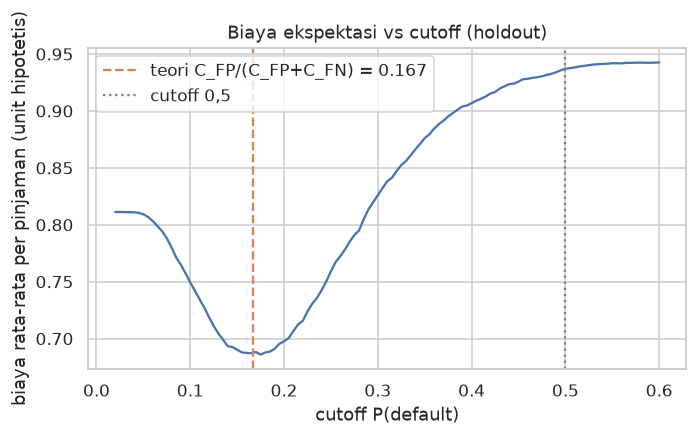

Cutoff empiris terbaik ≈ 0.175; biaya = 0.6860; biaya pada cutoff 0,5 = 0.9371


In [24]:
C_FN, C_FP = 5.0, 1.0   # asumsi ilustrasi, bukan dari dataset
proba_cal = strategies["Tanpa penanganan"].predict_proba(Xte)[:, 1]
cutoffs = np.linspace(0.02, 0.6, 117)
costs = [(C_FN * np.sum((proba_cal <= c) & (yte == 1)) + C_FP * np.sum((proba_cal > c) & (yte == 0))) / len(yte)
         for c in cutoffs]
best = cutoffs[int(np.argmin(costs))]
theory = C_FP / (C_FP + C_FN)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cutoffs, costs)
ax.axvline(theory, color="C1", ls="--", label=f"teori C_FP/(C_FP+C_FN) = {theory:.3f}")
ax.axvline(0.5, color="grey", ls=":", label="cutoff 0,5")
ax.set(xlabel="cutoff P(default)", ylabel="biaya rata-rata per pinjaman (unit hipotetis)",
       title="Biaya ekspektasi vs cutoff (holdout)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Cutoff empiris terbaik ≈ {best:.3f}; biaya = {min(costs):.4f}; biaya pada cutoff 0,5 = {costs[int(np.argmin(np.abs(cutoffs - 0.5)))]:.4f}")

**Interpretasi dan catatan belajar.** Cutoff empiris dengan biaya terendah (≈0,175) berada dekat nilai teoretis 1/6≈0,167, jauh di bawah 0,5; biaya rata-rata turun dari ≈0,94 menjadi ≈0,69 unit per pinjaman. Menolak semua pinjaman (cutoff mendekati 0) pun berbiaya ≈0,81. Pada asumsi biaya ini, menurunkan cutoff lebih masuk akal daripada melakukan resampling yang merusak kalibrasi. Bila rasio biaya berubah, cutoff optimal ikut berubah; karena itu biaya harus ditentukan dari konteks bisnis, bukan dipilih agar metrik tertentu tampak bagus.

<a id="c5-29"></a>
## Exploring the Predictions

*Acuan: cetak 234; PDF 252. Jenis: Reproduksi Python buku; GAM memakai LogisticGAM.*

Satu metrik tidak menunjukkan **bagaimana** model memisahkan kelas. Buku membandingkan aturan klasifikasi empat model pada `loan3000` dengan dua prediktor: decision tree, LDA, regresi logistik, dan regresi logistik dengan GAM. Untuk dua prediktor, batas keputusan dapat digambar langsung.

**Catatan adaptasi:** kode Python buku memakai `LinearGAM` (regresi Gaussian pada target 0/1) lalu memotong prediksi di 0,5; notebook memakai `LogisticGAM`, padanan GAM binomial pada R. Regresi logistik memakai pengaturan default scikit-learn (penalti L2 ringan, C=1) seperti kode buku. Target 0/1 eksplisit dipakai untuk semua model.

Lambda LogisticGAM terpilih: [np.float64(1000.0), np.float64(1000.0)] | effective dof: 4.52


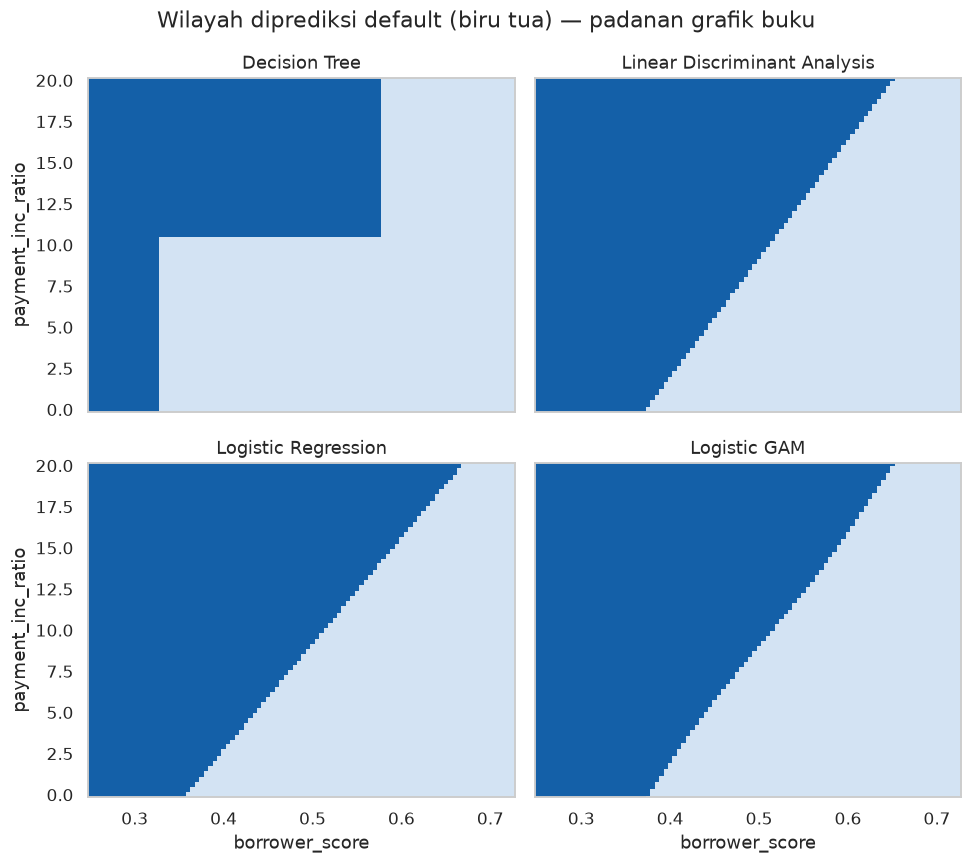

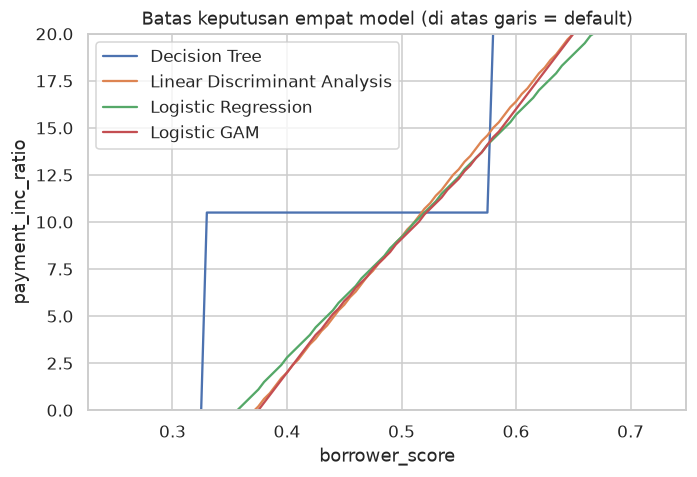

,accuracy in-sample,AUC in-sample
model,,
Decision Tree,0.6110,0.6671
Linear Discriminant Analysis,0.6290,0.6832
Logistic Regression,0.6283,0.6833
Logistic GAM,0.6260,0.6833


In [25]:
X2 = loan3000[["borrower_score", "payment_inc_ratio"]]
y2 = loan3000["y"]
tree_model = DecisionTreeClassifier(random_state=SEED, criterion="entropy", min_impurity_decrease=0.003).fit(X2, y2)
lda_model = LinearDiscriminantAnalysis().fit(X2, y2)
logit_model = LogisticRegression().fit(X2, y2)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gam_model = LogisticGAM(s(0) + s(1)).gridsearch(X2.to_numpy(), y2.to_numpy(), progress=False)
print("Lambda LogisticGAM terpilih:", [round(l[0], 3) for l in gam_model.lam],
      "| effective dof:", round(gam_model.statistics_["edof"], 2))

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
grid2 = pd.DataFrame({"borrower_score": xx.ravel(), "payment_inc_ratio": yy.ravel()})
models = {"Decision Tree": tree_model, "Linear Discriminant Analysis": lda_model,
          "Logistic Regression": logit_model, "Logistic GAM": gam_model}
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
boundary, fit_rows = {}, []
for ax, (title, model) in zip(axes.flat, models.items()):
    if title == "Logistic GAM":
        Z = (model.predict_proba(grid2.to_numpy()) > 0.5).astype(int)
        train_proba = model.predict_proba(X2.to_numpy())
    else:
        Z = model.predict(grid2)
        train_proba = model.predict_proba(X2)[:, 1]
    Z = Z.reshape(xx.shape)
    boundary[title] = yvalues[np.argmax(Z > 0, axis=0)]
    boundary[title][Z[-1, :] == 0] = yvalues[-1]
    ax.pcolormesh(xx, yy, Z, cmap="Blues", vmin=-0.3, vmax=1.3, shading="auto")
    ax.set(title=title)
    fit_rows.append({"model": title, "accuracy in-sample": accuracy_score(y2, train_proba > 0.5),
                     "AUC in-sample": roc_auc_score(y2, train_proba)})
for ax in axes[1]: ax.set_xlabel("borrower_score")
for ax in axes[:, 0]: ax.set_ylabel("payment_inc_ratio")
fig.suptitle("Wilayah diprediksi default (biru tua) — padanan grafik buku")
plt.tight_layout(); plt.show()

boundaries = pd.DataFrame(boundary, index=xvalues).rename_axis("borrower_score")
ax = boundaries.plot(figsize=(6.5, 4.5))
ax.set(ylabel="payment_inc_ratio", ylim=(0, 20),
       title="Batas keputusan empat model (di atas garis = default)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(fit_rows).set_index("model").round(4))

**Interpretasi dan catatan belajar.** LDA dan regresi logistik menghasilkan garis hampir identik: keduanya model linear dengan dua prediktor. GAM memilih penalti terbesar pada grid bawaan (λ=1000, ±4,5 derajat bebas efektif), sehingga batasnya praktis lurus: data tidak menunjukkan kelengkungan yang cukup kuat. Decision tree membentuk batas bertangga karena membagi ruang dengan aturan "if-then" sejajar sumbu; aturan tree ini dibahas detail di Bab 6. Metrik di tabel adalah in-sample dan mirip satu sama lain; perbedaan bentuk batas lebih menonjol daripada perbedaan metrik, terutama di wilayah dengan sedikit data (skor ekstrem atau rasio pembayaran besar).

<a id="c5-30"></a>
## Summary

*Acuan: cetak 236; PDF 254. Jenis: Teori.*

Classification memprediksi kelas dengan mengestimasi probabilitas lalu memilih cutoff. Naive Bayes memberi contoh aturan Bayes dengan asumsi independensi; LDA mencari arah pemisah linear; regresi logistik memodelkan log-odds dan memberi koefisien yang dapat ditafsirkan sebagai odds ratio. Evaluasi harus memisahkan kemampuan ranking (ROC/AUC, lift) dari keputusan pada cutoff tertentu (confusion matrix, precision, recall, specificity). Pada data tidak seimbang, resampling dan pembobotan mengubah tingkat prediksi kelas langka, tetapi kalibrasi dan biaya keputusan perlu diperhatikan.

**Latihan:** jelaskan mengapa tanda koefisien bisa terbalik antara scikit-learn dan R; hitung perubahan probabilitas (bukan odds) ketika `purpose_` berubah dari `credit_card` ke `small_business` pada satu record; jelaskan mengapa accuracy 81% baseline tidak berarti model bagus; tunjukkan mengapa SMOTE pada dummy dapat menghasilkan data mustahil; tentukan cutoff jika biaya FN = 10 × FP.

**Batas hasil:** sebagian besar metrik reproduksi buku adalah in-sample; holdout tambahan masih dipengaruhi `borrower_score` yang dibuat dari outcome seluruh data. Belum ada validasi waktu (pinjaman masa depan), analisis keadilan/diskriminasi kredit, atau biaya nyata. Model ini latihan metode, bukan sistem persetujuan kredit.

**Bacaan lanjutan:** buku mencantumkan referensi di akhir subbab, misalnya *The Elements of Statistical Learning* (Hastie, Tibshirani, Friedman), *An Introduction to Statistical Learning* (James dkk.), *Data Mining for Business Analytics* (Shmueli dkk.), dan buku khusus regresi logistik seperti karya Hosmer–Lemeshow. Rujuk buku untuk daftar lengkap.

## Referensi dan atribusi

- Peter Bruce, Andrew Bruce, Peter Gedeck. *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi 2, O’Reilly, 2020. ISBN 978-1-492-07294-2, Bab 5.
- [Kode dan dataset resmi pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); sumber khusus: `python/code/Chapter 5 - Classification.py` dan notebook pendamping. Copyright kode upstream © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck. Modifikasi untuk tugas: penjelasan Indonesia, target 0/1 eksplisit, fit logistik tanpa penalti modern, seed, perbaikan partial residual, pemeriksaan hasil, dan tambahan belajar yang ditandai. Lisensi GPL-3.0: lihat [LICENSE](LICENSE).
- Dokumentasi `imbalanced-learn` (SMOTE/ADASYN/SMOTENC) dan `pygam` (`LogisticGAM`) dipakai untuk menyesuaikan API.

**Refleksi mahasiswa:**